# Personalized Video Game Completion Time Prediction
### Synthetic player data with real game titles

## Importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Loading the dataset

In [2]:
import os

path = 'gaming_player_completion_dataset.csv'
if not os.path.exists(path):
    path = '../data/gaming_player_completion_dataset.csv'

df = pd.read_csv(path)
df.head(10)

,Player_ID,Gaming_Experience,Years_Of_Experience,Preferred_Playstyle,Preferred_Difficulty,Game_ID,Game_Name,Game_Genre,Game_Difficulty,Open_World,...,Side_Quests_Completed,Missions_Completed,Average_Mission_Time_Minutes,Collectibles_Found,Combat_Efficiency,Puzzle_Solving_Time_Minutes,Average_Daily_Gaming_Hours,Sessions_Per_Week,Main_Story_Progress_Percentage,Completion_Time_Hours
0,SYN_P01471,Advanced,7.7,Explorer,Hard,G004,Cyberpunk 2077,RPG,Normal,Yes,...,1.0,1.0,49.4,22.0,62.0,7.8,2.8,7.0,2.5,32.3
1,SYN_P03903,Advanced,10.5,Balanced,Normal,G047,Star Wars Jedi: Fallen Order,Action,Hard,Yes,...,3.0,0.0,85.2,9.0,38.6,9.4,1.7,6.0,12.4,19.2
2,SYN_P02549,Advanced,9.8,Explorer,Normal,G061,Alan Wake,Adventure,Normal,No,...,0.0,1.0,63.4,9.0,51.2,14.7,5.0,13.0,29.9,8.9
3,SYN_P05878,Beginner,1.1,Balanced,Easy,G021,Dark Souls II: Scholar of the First Sin,RPG,Very_Hard,No,...,1.0,0.0,64.6,7.0,10.5,7.2,3.3,8.0,5.1,66.8
4,SYN_P09035,Advanced,9.7,Balanced,Hard,G003,Baldur's Gate 3,RPG,Normal,No,...,1.0,0.0,73.0,4.0,65.4,2.8,2.2,8.0,1.7,48.4
5,SYN_P07362,Expert,24.8,Speedrunner,Normal,G010,Kingdom Come: Deliverance,RPG,Normal,Yes,...,1.0,2.0,34.8,1.0,50.4,1.8,1.8,7.0,7.1,25.8
6,SYN_P08786,Intermediate,2.5,Speedrunner,Normal,G021,Dark Souls II: Scholar of the First Sin,RPG,Very-Hard,No,...,0.0,0.0,74.8,1.0,22.1,6.7,NaN,7.0,8.1,34.6
7,SYN_P06701,Intermediate,2.3,Speedrunner,Easy,G043,Half-Life,Action,HARD,No,...,0.0,3.0,24.8,2.0,34.6,3.6,1.8,2.0,5.9,15.9
8,SYN_P08342,Intermediate,2.9,Speedrunner,Easy,G027,Doom,Action,Hard,N,...,0.0,2.0,40.2,4.0,NaN,3.5,1.7,6.0,17.9,13.5
9,SYN_P04276,Expert,18.1,Speedrunner,Hard,G054,BioShock Infinite,Adventure,Normal,No,...,0.0,8.0,9.0,3.0,78.4,2.3,3.3,7.0,19.0,6.6


## Last 5 rows

In [3]:
df.tail()

,Player_ID,Gaming_Experience,Years_Of_Experience,Preferred_Playstyle,Preferred_Difficulty,Game_ID,Game_Name,Game_Genre,Game_Difficulty,Open_World,...,Side_Quests_Completed,Missions_Completed,Average_Mission_Time_Minutes,Collectibles_Found,Combat_Efficiency,Puzzle_Solving_Time_Minutes,Average_Daily_Gaming_Hours,Sessions_Per_Week,Main_Story_Progress_Percentage,Completion_Time_Hours
51245,SYN_P02762,Intermediate,5.8 years,Balanced,Hard,G012,divinity: original sin ii,RPG,Normal,No,...,4.0,0.0,56.9,10.0,NaN,8.4,0.7,2.0,1.4,63.3
51246,SYN_P00181,Intermediate,5.4,Balanced,Hard,G045,Borderlands 2,Action,Normal,Yes,...,0.0,1.0,73.0,11.0,29.1,2.1,4.8,6.0,4.3,56.7
51247,SYN_P07681,Beginner,0.4,Completionist,Normal,G086,Red Dead Redemption 2,Open_World,Normal,Yes,...,8.0,3.0,21.8,14.0,34.1,6.3,1.3,4.0,2.2,76.9
51248,SYN_P02106,Expert,10.8,Explorer,Hard,G093,Mafia: Definitive Edition,Open_World,Normal,Yes,...,1.0,2.0,33.5,17.0,68.8,1.4,3.9,14.0,10.2,9.1
51249,SYN_P09933,Advanced,5.9,Explorer,Hard,G072,Age of Empires II: Definitive Edition,Strategy,Normal,N,...,0.0,2.0,35.9,10.0,49.7,5.4,1.4,5.0,6.3,49.4


## Shape and column names

In [4]:
print(df.shape)
print(df.columns.tolist())

(51250, 27)
['Player_ID', 'Gaming_Experience', 'Years_Of_Experience', 'Preferred_Playstyle', 'Preferred_Difficulty', 'Game_ID', 'Game_Name', 'Game_Genre', 'Game_Difficulty', 'Open_World', 'Mission_Count', 'Main_Story_Complexity', 'Side_Quest_Availability', 'Puzzle_Intensity', 'Exploration_Percentage', 'Death_Count', 'Retry_Count', 'Side_Quests_Completed', 'Missions_Completed', 'Average_Mission_Time_Minutes', 'Collectibles_Found', 'Combat_Efficiency', 'Puzzle_Solving_Time_Minutes', 'Average_Daily_Gaming_Hours', 'Sessions_Per_Week', 'Main_Story_Progress_Percentage', 'Completion_Time_Hours']


## Data types and dataset information

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51250 entries, 0 to 51249
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Player_ID                       51250 non-null  str    
 1   Gaming_Experience               50532 non-null  str    
 2   Years_Of_Experience             49726 non-null  str    
 3   Preferred_Playstyle             49999 non-null  str    
 4   Preferred_Difficulty            50010 non-null  str    
 5   Game_ID                         51250 non-null  str    
 6   Game_Name                       50491 non-null  str    
 7   Game_Genre                      51250 non-null  str    
 8   Game_Difficulty                 51250 non-null  str    
 9   Open_World                      51250 non-null  str    
 10  Mission_Count                   50743 non-null  float64
 11  Main_Story_Complexity           50239 non-null  str    
 12  Side_Quest_Availability         50520 non-n

## Descriptive statistics

In [6]:
df.describe()

,Mission_Count,Exploration_Percentage,Death_Count,Retry_Count,Side_Quests_Completed,Missions_Completed,Average_Mission_Time_Minutes,Collectibles_Found,Combat_Efficiency,Puzzle_Solving_Time_Minutes,Sessions_Per_Week,Main_Story_Progress_Percentage
count,50743.000000,50234.000000,50513.000000,50543.000000,50499.000000,50853.000000,50744.000000,49982.000000,49673.000000,50488.000000,47168.000000,50712.000000
mean,25.157480,43.758536,3.964564,3.304236,1.669023,2.099463,47.432427,8.524409,43.610881,8.224760,5.709316,10.769605
std,22.447233,18.974091,5.168679,3.453619,1.766769,2.791479,24.235518,5.177507,15.007608,20.411889,2.944355,10.836875
min,4.000000,2.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.700000,1.000000,0.400000
25%,11.000000,30.300000,1.000000,1.000000,0.000000,0.000000,24.100000,4.000000,32.800000,3.400000,4.000000,4.000000
50%,17.000000,44.100000,2.000000,2.000000,1.000000,1.000000,53.900000,8.000000,43.600000,6.200000,5.000000,7.400000
75%,30.000000,57.600000,5.000000,4.000000,3.000000,3.000000,68.200000,12.000000,54.500000,10.500000,7.000000,13.700000
max,113.000000,129.700000,80.000000,50.000000,8.000000,106.000000,106.200000,37.000000,124.900000,991.000000,39.000000,139.900000


## Missing values and duplicates

In [7]:
print(df.isnull().sum())
print(df.duplicated().sum())

Player_ID                            0
Gaming_Experience                  718
Years_Of_Experience               1524
Preferred_Playstyle               1251
Preferred_Difficulty              1240
Game_ID                              0
Game_Name                          759
Game_Genre                           0
Game_Difficulty                      0
Open_World                           0
Mission_Count                      507
Main_Story_Complexity             1011
Side_Quest_Availability            730
Puzzle_Intensity                  1027
Exploration_Percentage            1016
Death_Count                        737
Retry_Count                        707
Side_Quests_Completed              751
Missions_Completed                 397
Average_Mission_Time_Minutes       506
Collectibles_Found                1268
Combat_Efficiency                 1577
Puzzle_Solving_Time_Minutes        762
Average_Daily_Gaming_Hours        4050
Sessions_Per_Week                 4082
Main_Story_Progress_Perce

## Unique players and games

In [8]:
print("Players:", df['Player_ID'].nunique())
print("Game IDs:", df['Game_ID'].nunique())
print("Game names:", df['Game_Name'].nunique())

Players: 10198
Game IDs: 206
Game names: 416


## Saving a copy of the original data

In [9]:
df_original = df.copy()

## Checking category labels

In [10]:
cat_cols = ['Gaming_Experience', 'Preferred_Playstyle', 'Preferred_Difficulty', 'Game_Genre', 'Game_Difficulty',
            'Open_World', 'Main_Story_Complexity', 'Side_Quest_Availability', 'Puzzle_Intensity']

for i in cat_cols:
    print(i, df[i].nunique(), df[i].unique()[:12])

Gaming_Experience 26 <StringArray>
[     'Advanced',      'Beginner',        'Expert',  'Intermediate',
   'Intermedate',       ' Expert',      'advanced',             nan,
  'INTERMEDIATE',      'beginner',       'Advance', ' Intermediate']
Length: 12, dtype: str
Preferred_Playstyle 33 <StringArray>
[      'Explorer',       'Balanced',    'Speedrunner',  'Story_Focused',
              nan,  'Completionist',  'COMPLETIONIST', ' Story_Focused',
       'BALANCED',      ' Balanced',       'balanced',       'explorer']
Length: 12, dtype: str
Preferred_Difficulty 15 <StringArray>
[   'Hard',  'Normal',    'Easy',       nan,   ' Hard',    'easy',   'Hard ',
    'HARD', ' Normal',  'normal', 'Normal ',    'hard']
Length: 12, dtype: str
Game_Genre 36 <StringArray>
[       'RPG',     'Action',  'Adventure', 'Open_World',       'RPG ',
   'Strategy',       ' RPG',    ' Action',   'Survival', 'Adventure ',
 'Open World',  'Adventrue']
Length: 12, dtype: str
Game_Difficulty 24 <StringArray>
[   'N

## Removing exact duplicate rows

In [11]:
print("Before:", df.shape)
df = df.drop_duplicates()
print("After:", df.shape)

Before: (51250, 27)


After: (50500, 27)


## Removing extra spaces in IDs and names

In [12]:
for i in ['Player_ID', 'Game_ID', 'Game_Name']:
    df[i] = df[i].str.strip()

print("Players:", df['Player_ID'].nunique())
print("Game IDs:", df['Game_ID'].nunique())

Players: 10000
Game IDs: 100


## Removing repeated player-game records

In [13]:
print("Repeated records:", df.duplicated(subset=['Player_ID', 'Game_ID']).sum())
df = df.drop_duplicates(subset=['Player_ID', 'Game_ID'], keep='first')
print("After:", df.shape)

Repeated records: 500
After: (50000, 27)


## Fixing game names

In [14]:
print("Before:", df['Game_Name'].nunique(), "| missing:", df['Game_Name'].isnull().sum())

correct_names = df.groupby('Game_ID')['Game_Name'].agg(lambda s: s.mode()[0])
df['Game_Name'] = df['Game_ID'].map(correct_names)

print("After:", df['Game_Name'].nunique(), "| missing:", df['Game_Name'].isnull().sum())

Before: 294 | missing: 746
After: 100 | missing: 0


## Converting text values to numbers

In [15]:
text_cols = ['Years_Of_Experience', 'Average_Daily_Gaming_Hours', 'Completion_Time_Hours']

print(df[text_cols].dtypes)

for i in text_cols:
    df[i] = df[i].astype(str).str.replace(',', '.').str.replace('years', '').str.replace('hrs', '').str.replace('h', '')
    df[i] = pd.to_numeric(df[i].str.strip(), errors='coerce')

print(df[text_cols].dtypes)

Years_Of_Experience           str
Average_Daily_Gaming_Hours    str
Completion_Time_Hours         str
dtype: object


Years_Of_Experience           float64
Average_Daily_Gaming_Hours    float64
Completion_Time_Hours         float64
dtype: object


## Fixing inconsistent category labels

In [16]:
valid = {
    'Gaming_Experience': ['Beginner', 'Intermediate', 'Advanced', 'Expert'],
    'Preferred_Playstyle': ['Explorer', 'Completionist', 'Speedrunner', 'Story_Focused', 'Balanced'],
    'Preferred_Difficulty': ['Easy', 'Normal', 'Hard'],
    'Game_Genre': ['RPG', 'Action', 'Adventure', 'Strategy', 'Survival', 'Open_World'],
    'Game_Difficulty': ['Easy', 'Normal', 'Hard', 'Very_Hard'],
    'Open_World': ['Yes', 'No'],
    'Main_Story_Complexity': ['Low', 'Medium', 'High'],
    'Side_Quest_Availability': ['Yes', 'No'],
    'Puzzle_Intensity': ['Low', 'Medium', 'High'],
}

typos = {'begginer': 'beginner', 'beginer': 'beginner', 'intermedate': 'intermediate', 'intermidiate': 'intermediate',
         'advance': 'advanced', 'complitionist': 'completionist', 'storyfocussed': 'storyfocused',
         'stratergy': 'strategy', 'adventrue': 'adventure', 'survial': 'survival',
         'y': 'yes', 'true': 'yes', '1': 'yes', 'n': 'no', 'false': 'no', '0': 'no'}


def simplify(text):
    text = str(text).lower().strip()
    for ch in [' ', '_', '-', '.']:
        text = text.replace(ch, '')
    return typos.get(text, text)


for col in valid:
    lookup = {simplify(label): label for label in valid[col]}
    df[col] = df[col].map(lambda x: lookup.get(simplify(x)) if pd.notnull(x) else x)
    print(col, df[col].unique())

Gaming_Experience <StringArray>
['Advanced', 'Beginner', 'Expert', 'Intermediate', nan]
Length: 5, dtype: str
Preferred_Playstyle <StringArray>
['Explorer', 'Balanced', 'Speedrunner', 'Story_Focused', nan, 'Completionist']
Length: 6, dtype: str


Preferred_Difficulty <StringArray>
['Hard', 'Normal', 'Easy', nan]
Length: 4, dtype: str


Game_Genre <StringArray>
['RPG', 'Action', 'Adventure', 'Open_World', 'Strategy', 'Survival']
Length: 6, dtype: str
Game_Difficulty <StringArray>
['Normal', 'Hard', 'Very_Hard', 'Easy']
Length: 4, dtype: str


Open_World <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Main_Story_Complexity <StringArray>
['High', 'Medium', nan, 'Low']
Length: 4, dtype: str
Side_Quest_Availability <StringArray>
['Yes', 'No', nan]
Length: 3, dtype: str


Puzzle_Intensity <StringArray>
['Medium', 'Low', nan, 'High']
Length: 4, dtype: str


## Filling missing game details from the same game

In [17]:
game_cols = ['Game_Genre', 'Game_Difficulty', 'Open_World', 'Mission_Count',
             'Main_Story_Complexity', 'Side_Quest_Availability', 'Puzzle_Intensity']

print("Before:", df[game_cols].isnull().sum().sum())

for i in game_cols:
    df[i] = df[i].fillna(df.groupby('Game_ID')[i].transform('first'))

print("After:", df[game_cols].isnull().sum().sum())

Before: 3208


After: 0


## Checking invalid values

In [18]:
invalid = {
    'Death_Count': df['Death_Count'] < 0,
    'Retry_Count': df['Retry_Count'] < 0,
    'Exploration_Percentage': df['Exploration_Percentage'] > 100,
    'Combat_Efficiency': df['Combat_Efficiency'] > 100,
    'Main_Story_Progress_Percentage': df['Main_Story_Progress_Percentage'] > 100,
    'Years_Of_Experience': (df['Years_Of_Experience'] < 0) | (df['Years_Of_Experience'] > 60),
    'Average_Daily_Gaming_Hours': df['Average_Daily_Gaming_Hours'] > 24,
    'Sessions_Per_Week': df['Sessions_Per_Week'] > 21,
    'Puzzle_Solving_Time_Minutes': df['Puzzle_Solving_Time_Minutes'] > 120,
    'Average_Mission_Time_Minutes': df['Average_Mission_Time_Minutes'] <= 0,
    'Missions_Completed': df['Missions_Completed'] > df['Mission_Count'],
    'Completion_Time_Hours': df['Completion_Time_Hours'] <= 0,
}

for i in invalid:
    print(i, invalid[i].sum())

Death_Count 112
Retry_Count 98
Exploration_Percentage 103
Combat_Efficiency 95
Main_Story_Progress_Percentage 47
Years_Of_Experience 75
Average_Daily_Gaming_Hours 48
Sessions_Per_Week 50
Puzzle_Solving_Time_Minutes 41
Average_Mission_Time_Minutes 49
Missions_Completed 73
Completion_Time_Hours 76


## Replacing invalid values with missing values

In [19]:
for i in invalid:
    df.loc[invalid[i], i] = np.nan

print(df[list(invalid)].isnull().sum())

Death_Count                        837
Retry_Count                        794
Exploration_Percentage            1109
Combat_Efficiency                 1643
Main_Story_Progress_Percentage     573
Years_Of_Experience               1574
Average_Daily_Gaming_Hours        4014
Sessions_Per_Week                 4041
Puzzle_Solving_Time_Minutes        787
Average_Mission_Time_Minutes       549
Missions_Completed                 465
Completion_Time_Hours              268
dtype: int64


## Checking completion times far above the game's usual time

In [20]:
game_median = df.groupby('Game_ID')['Completion_Time_Hours'].transform('median')
too_long = df['Completion_Time_Hours'] > 4 * game_median

print("Records above 4x the game's median:", too_long.sum())
df[too_long][['Game_Name', 'Completion_Time_Hours']].head(10)

Records above 4x the game's median: 101


,Game_Name,Completion_Time_Hours
900,Divinity: Original Sin II,424.0
1156,Watch Dogs 2,94.2
2136,Sekiro: Shadows Die Twice,128.1
2166,Doom Eternal,440.0
2194,Dark Souls II: Scholar of the First Sin,3696.0
2644,Portal 2,408.0
3043,Assassin's Creed II,1308.0
3950,Monster Hunter: World,210.9
4256,Devil May Cry 5,120.0
4881,Monster Hunter: World,248.2


In [21]:
df.loc[too_long, 'Completion_Time_Hours'] = np.nan

## Filling missing player details from the same player

In [22]:
player_cols = ['Gaming_Experience', 'Years_Of_Experience', 'Preferred_Playstyle', 'Preferred_Difficulty']
habit_cols = ['Average_Daily_Gaming_Hours', 'Sessions_Per_Week']

print("Before:", df[player_cols + habit_cols].isnull().sum().sum())

for i in player_cols:
    df[i] = df[i].fillna(df.groupby('Player_ID')[i].transform('first'))

for i in habit_cols:
    df[i] = df[i].fillna(df.groupby('Player_ID')[i].transform('median'))

print("After:", df[player_cols + habit_cols].isnull().sum().sum())

Before: 12781


After: 389


## Removing records without a completion time

In [23]:
print("Missing target:", df['Completion_Time_Hours'].isnull().sum())
df = df.dropna(subset=['Completion_Time_Hours']).reset_index(drop=True)
print("After:", df.shape, "| missing target:", df['Completion_Time_Hours'].isnull().sum())

Missing target: 369


After: (49631, 27) | missing target: 0


## Missing values after cleaning

In [24]:
print(df.isnull().sum())

Player_ID                            0
Gaming_Experience                   19
Years_Of_Experience                 39
Preferred_Playstyle                 30
Preferred_Difficulty                39
Game_ID                              0
Game_Name                            0
Game_Genre                           0
Game_Difficulty                      0
Open_World                           0
Mission_Count                        0
Main_Story_Complexity                0
Side_Quest_Availability              0
Puzzle_Intensity                     0
Exploration_Percentage            1095
Death_Count                        830
Retry_Count                        790
Side_Quests_Completed              729
Missions_Completed                 460
Average_Mission_Time_Minutes       545
Collectibles_Found                1228
Combat_Efficiency                 1629
Puzzle_Solving_Time_Minutes        783
Average_Daily_Gaming_Hours         135
Sessions_Per_Week                  124
Main_Story_Progress_Perce

## Outlier analysis (IQR)

In [25]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

for i in num_cols:
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df[i] < q1 - 1.5 * iqr) | (df[i] > q3 + 1.5 * iqr)).sum()
    print(i, outliers)

Years_Of_Experience 2211
Mission_Count 4229
Exploration_Percentage 0
Death_Count 3316
Retry_Count 3244
Side_Quests_Completed 269
Missions_Completed 2268
Average_Mission_Time_Minutes 0
Collectibles_Found 156
Combat_Efficiency 10
Puzzle_Solving_Time_Minutes 1427
Average_Daily_Gaming_Hours 1925
Sessions_Per_Week 1864
Main_Story_Progress_Percentage 3075
Completion_Time_Hours 2535


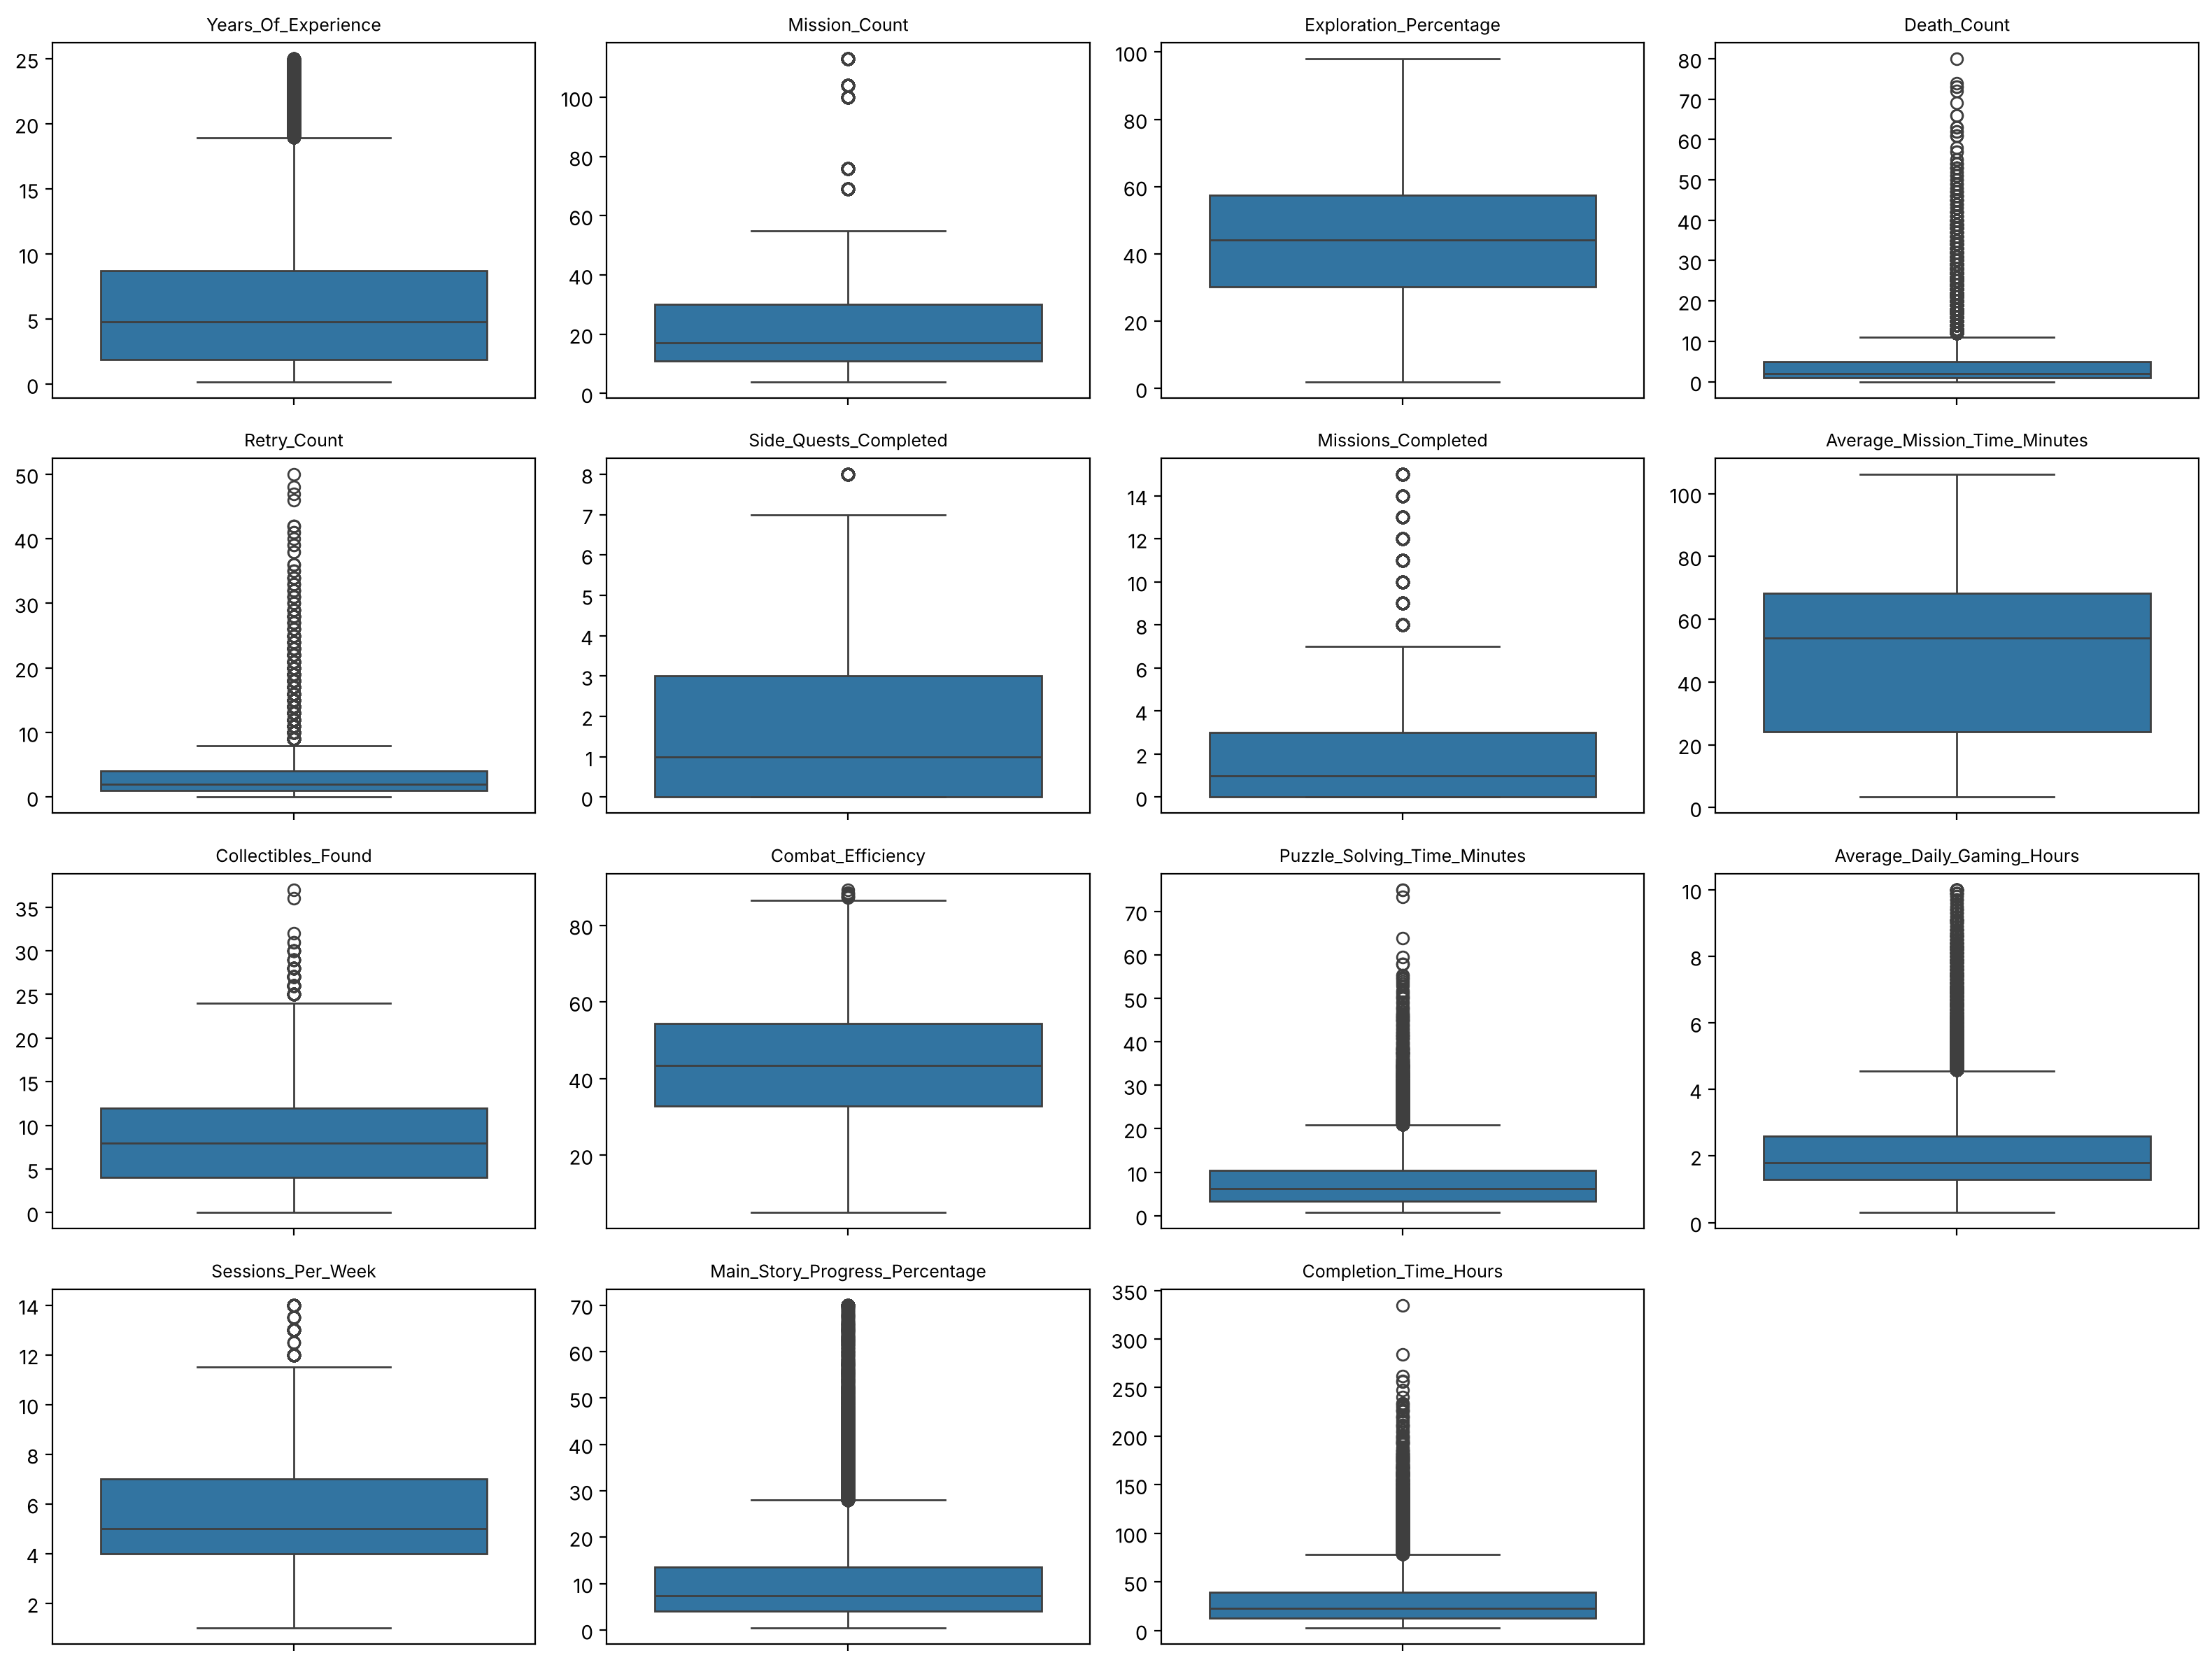

In [26]:
plt.figure(figsize=(16, 12))
for n, i in enumerate(num_cols):
    plt.subplot(4, 4, n + 1)
    sns.boxplot(y=df[i])
    plt.title(i, fontsize=9)
    plt.ylabel('')
plt.tight_layout()
plt.show()

## Before and after cleaning

In [27]:
print("Rows:", df_original.shape[0], "->", df.shape[0])
print("Missing values:", df_original.isnull().sum().sum(), "->", df.isnull().sum().sum())
print("Duplicate rows:", df_original.duplicated().sum(), "->", df.duplicated().sum())
print("Players:", df_original['Player_ID'].nunique(), "->", df['Player_ID'].nunique())
print("Game names:", df_original['Game_Name'].nunique(), "->", df['Game_Name'].nunique())
print("Genre labels:", df_original['Game_Genre'].nunique(), "->", df['Game_Genre'].nunique())

Rows: 51250 -> 49631
Missing values: 25351 -> 9044
Duplicate rows: 750 -> 0
Players: 10198 -> 9988
Game names: 416 -> 100
Genre labels: 36 -> 6


## Completion time distribution

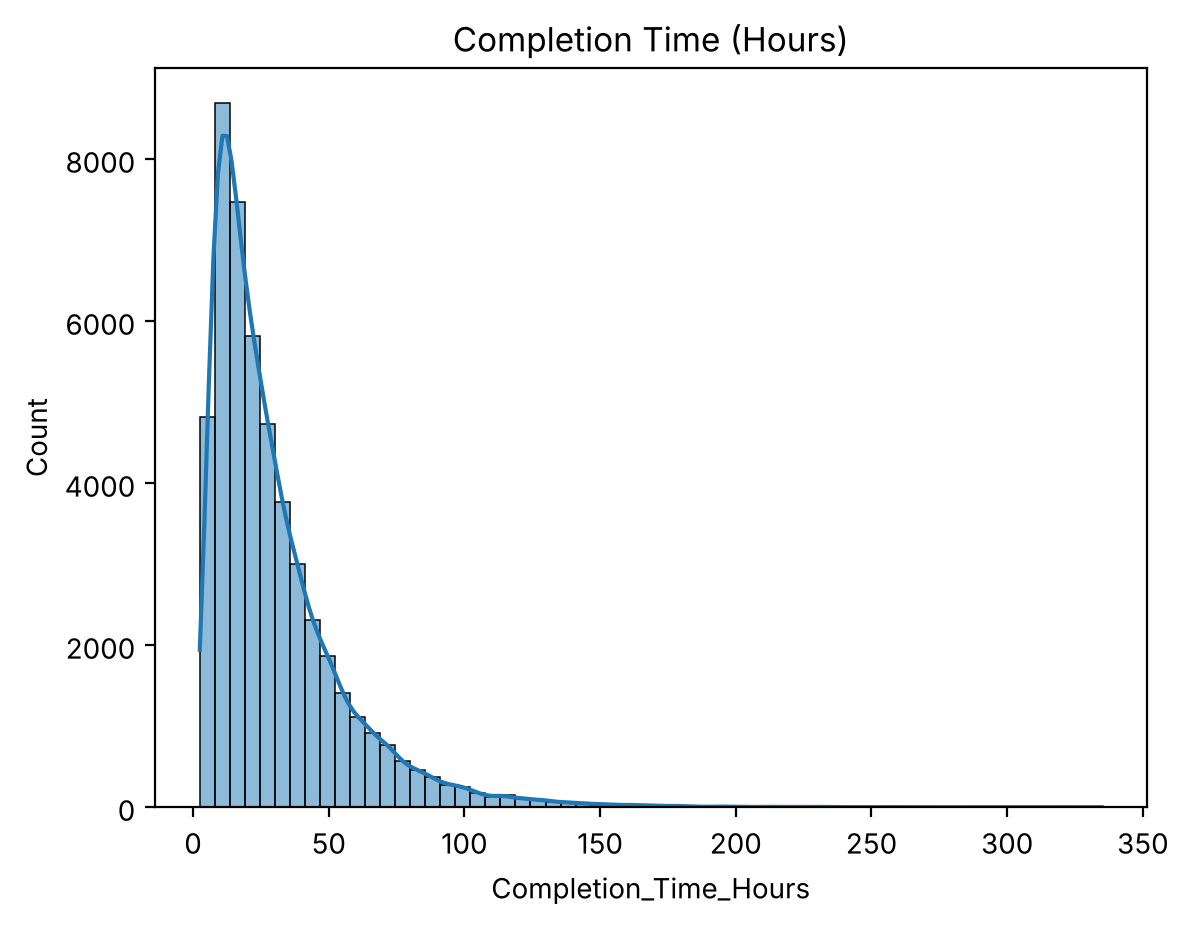

Skewness: 2.19677397563764


In [28]:
sns.histplot(df['Completion_Time_Hours'], bins=60, kde=True)
plt.title('Completion Time (Hours)')
plt.show()

print("Skewness:", df['Completion_Time_Hours'].skew())

## Most played games

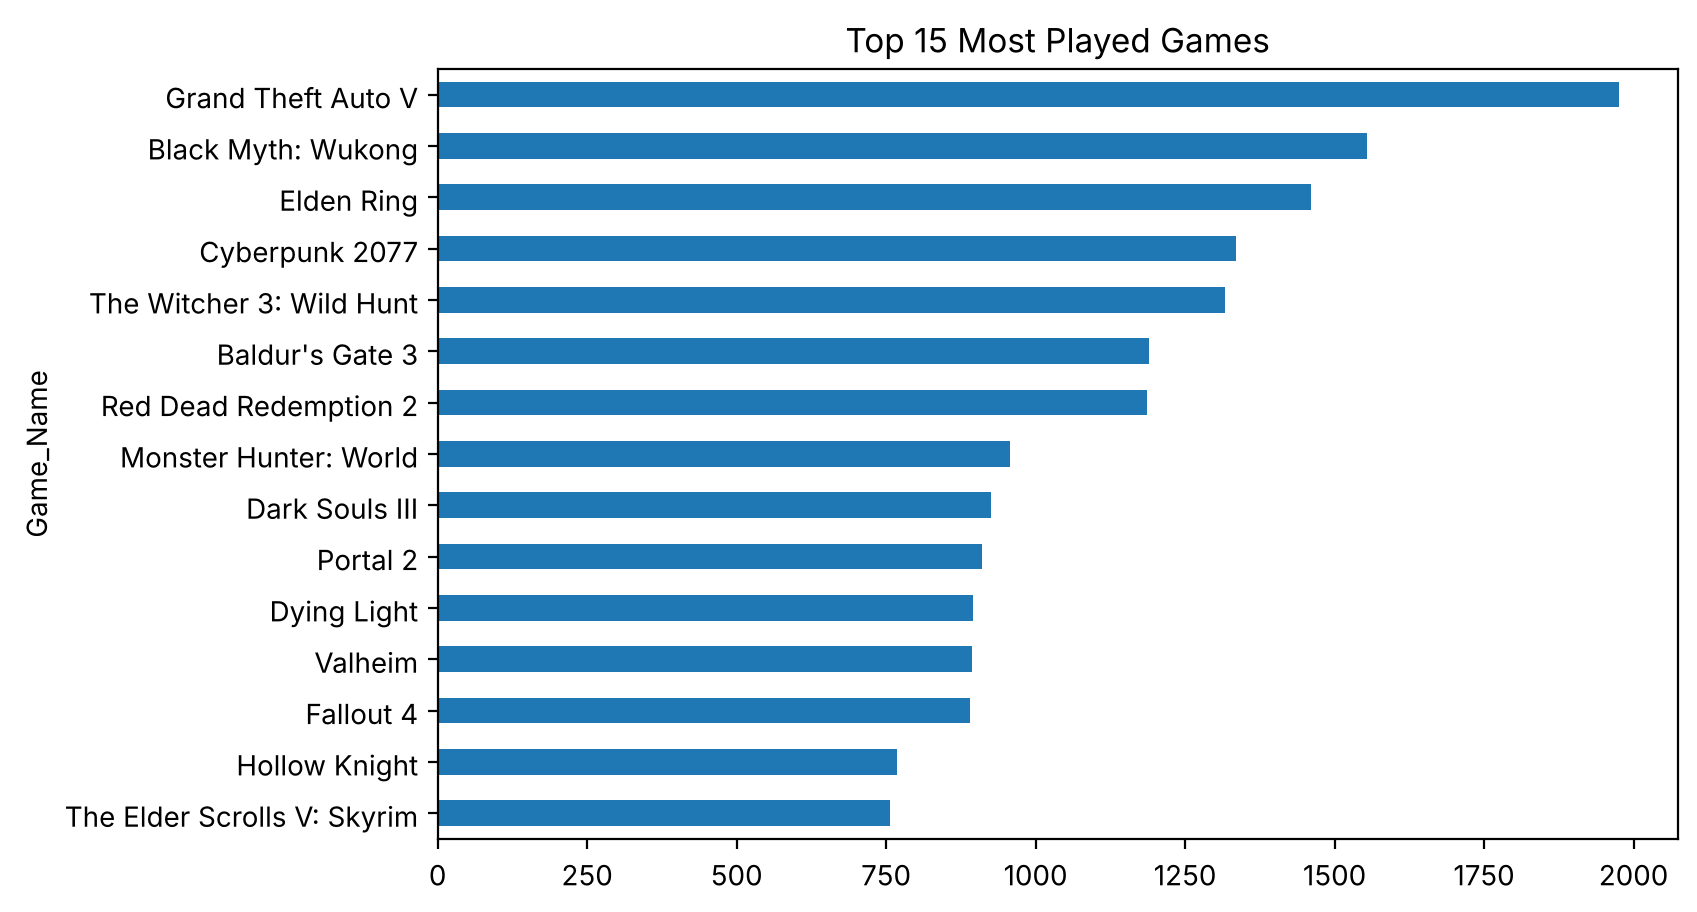

In [29]:
df['Game_Name'].value_counts().head(15).sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Top 15 Most Played Games')
plt.show()

## Median completion time per game

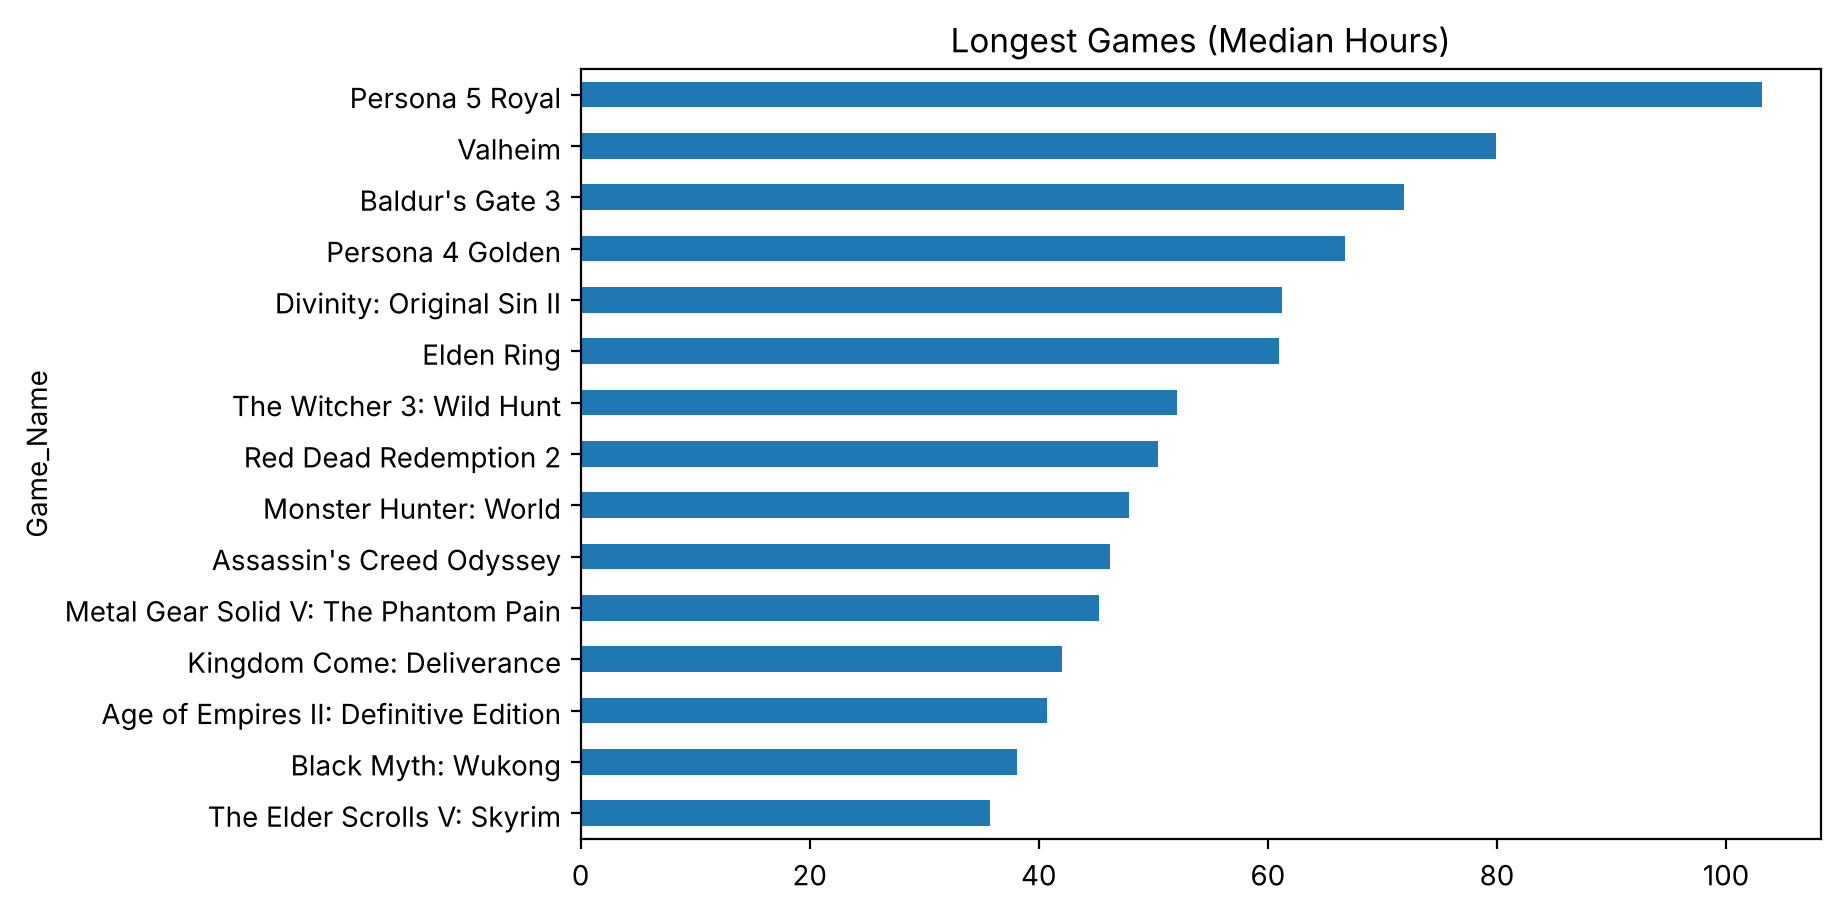

In [30]:
df.groupby('Game_Name')['Completion_Time_Hours'].median().sort_values().tail(15).plot(kind='barh', figsize=(8, 5))
plt.title('Longest Games (Median Hours)')
plt.show()

## Completion time by gaming experience

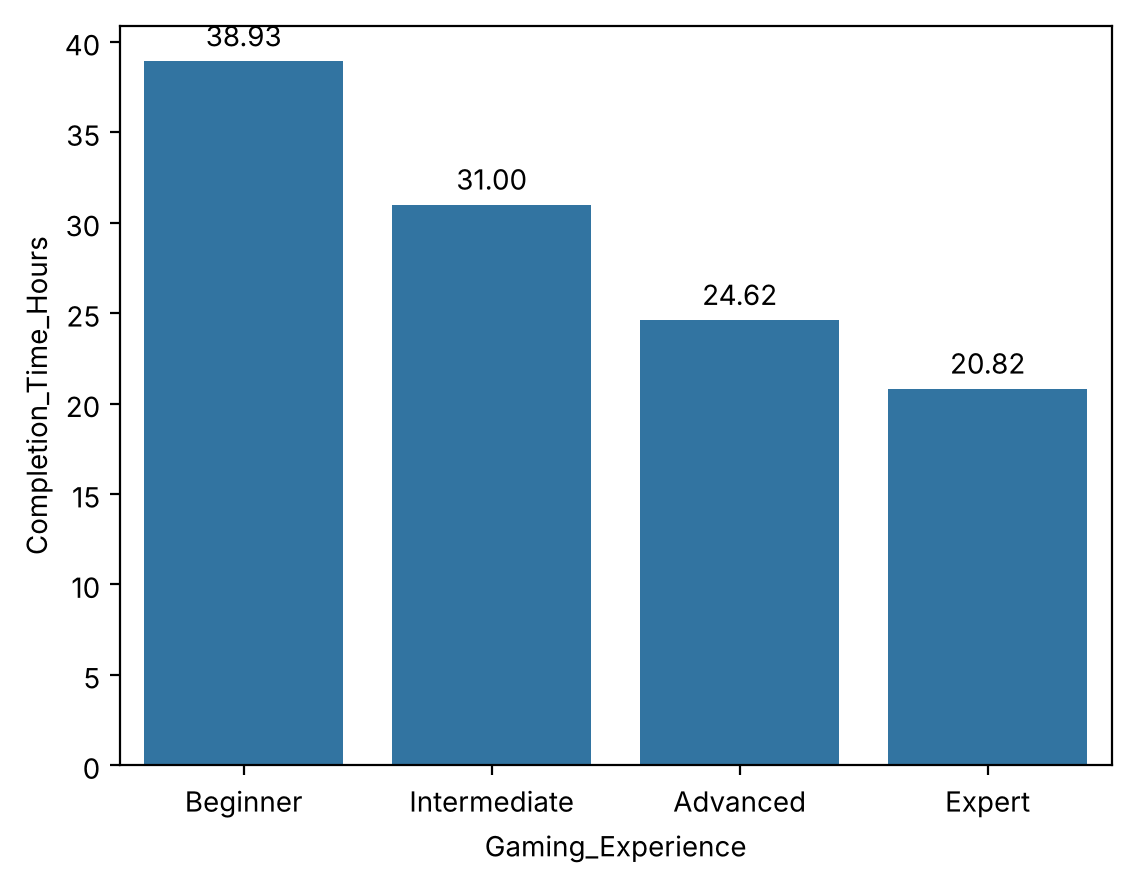

In [31]:
ax = sns.barplot(data=df, x='Gaming_Experience', y='Completion_Time_Hours', errorbar=None,
            order=['Beginner', 'Intermediate', 'Advanced', 'Expert'])
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.show()

## Completion time by playstyle

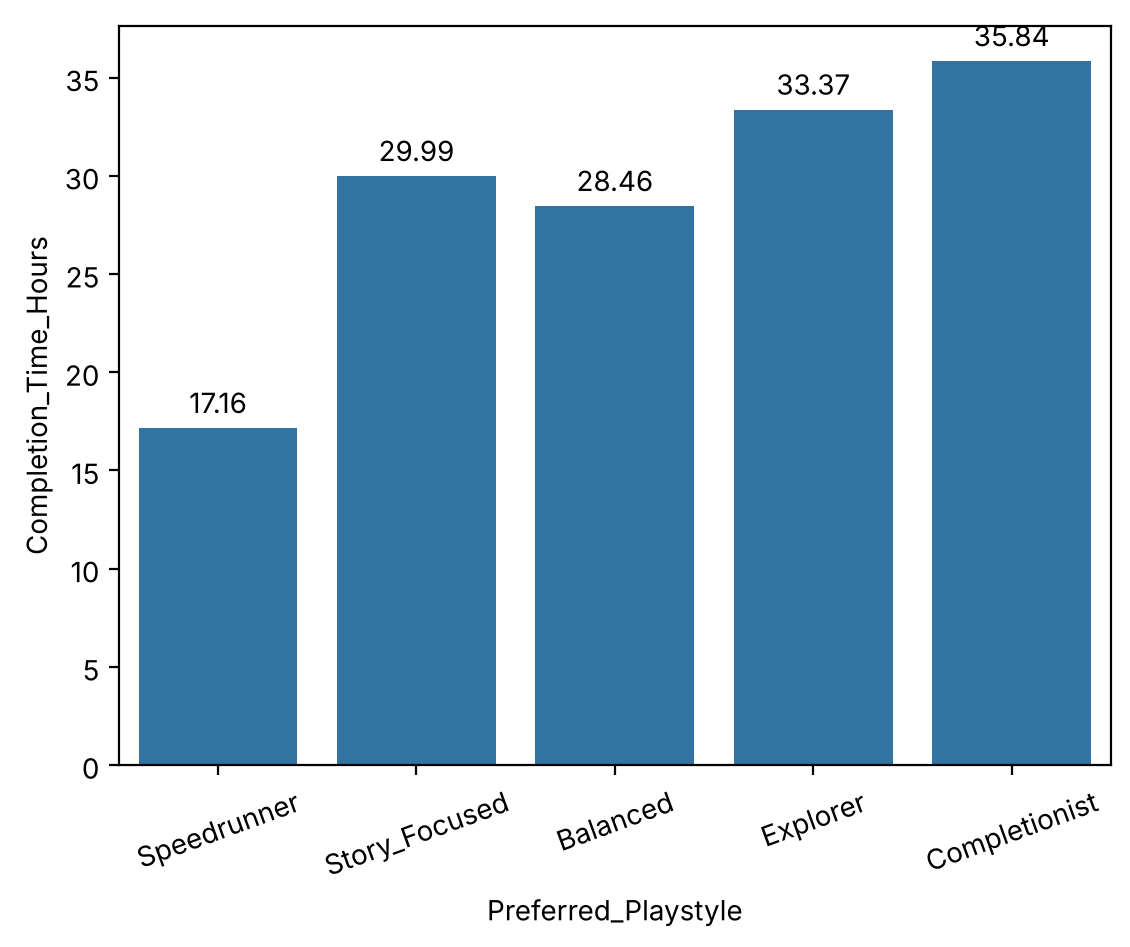

In [32]:
ax1 = sns.barplot(data=df, x='Preferred_Playstyle', y='Completion_Time_Hours', errorbar=None,
            order=['Speedrunner', 'Story_Focused', 'Balanced', 'Explorer', 'Completionist'])
plt.xticks(rotation=20)
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.2f', padding=3)
plt.show()

## Completion time by game genre

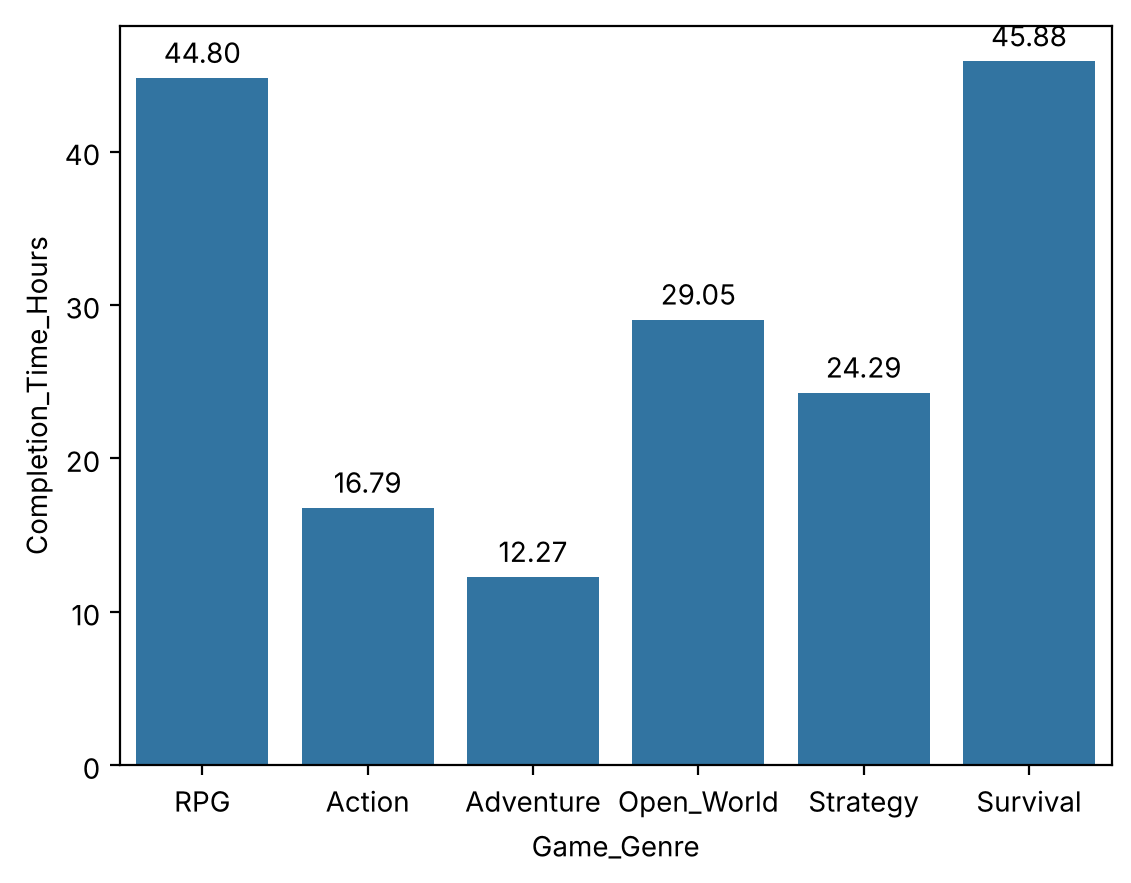

In [33]:
ax2 = sns.barplot(data=df, x='Game_Genre', y='Completion_Time_Hours', errorbar=None)
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.2f', padding=3)
plt.show()

## Completion time by game difficulty

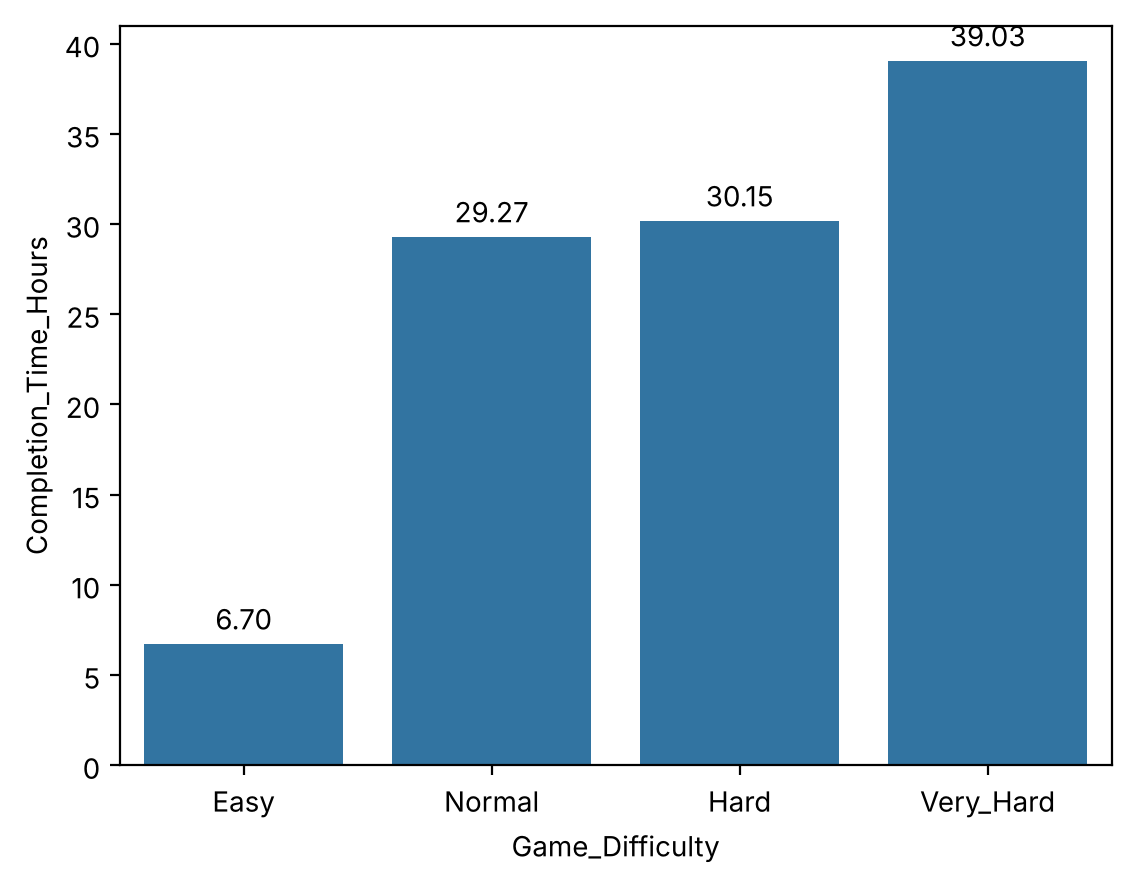

In [34]:
ax3 = sns.barplot(data=df, x='Game_Difficulty', y='Completion_Time_Hours', errorbar=None,
            order=['Easy', 'Normal', 'Hard', 'Very_Hard'])
for container in ax3.containers:
    ax3.bar_label(container, fmt='%.2f', padding=3)
plt.show()

## Completion time compared with each game's median

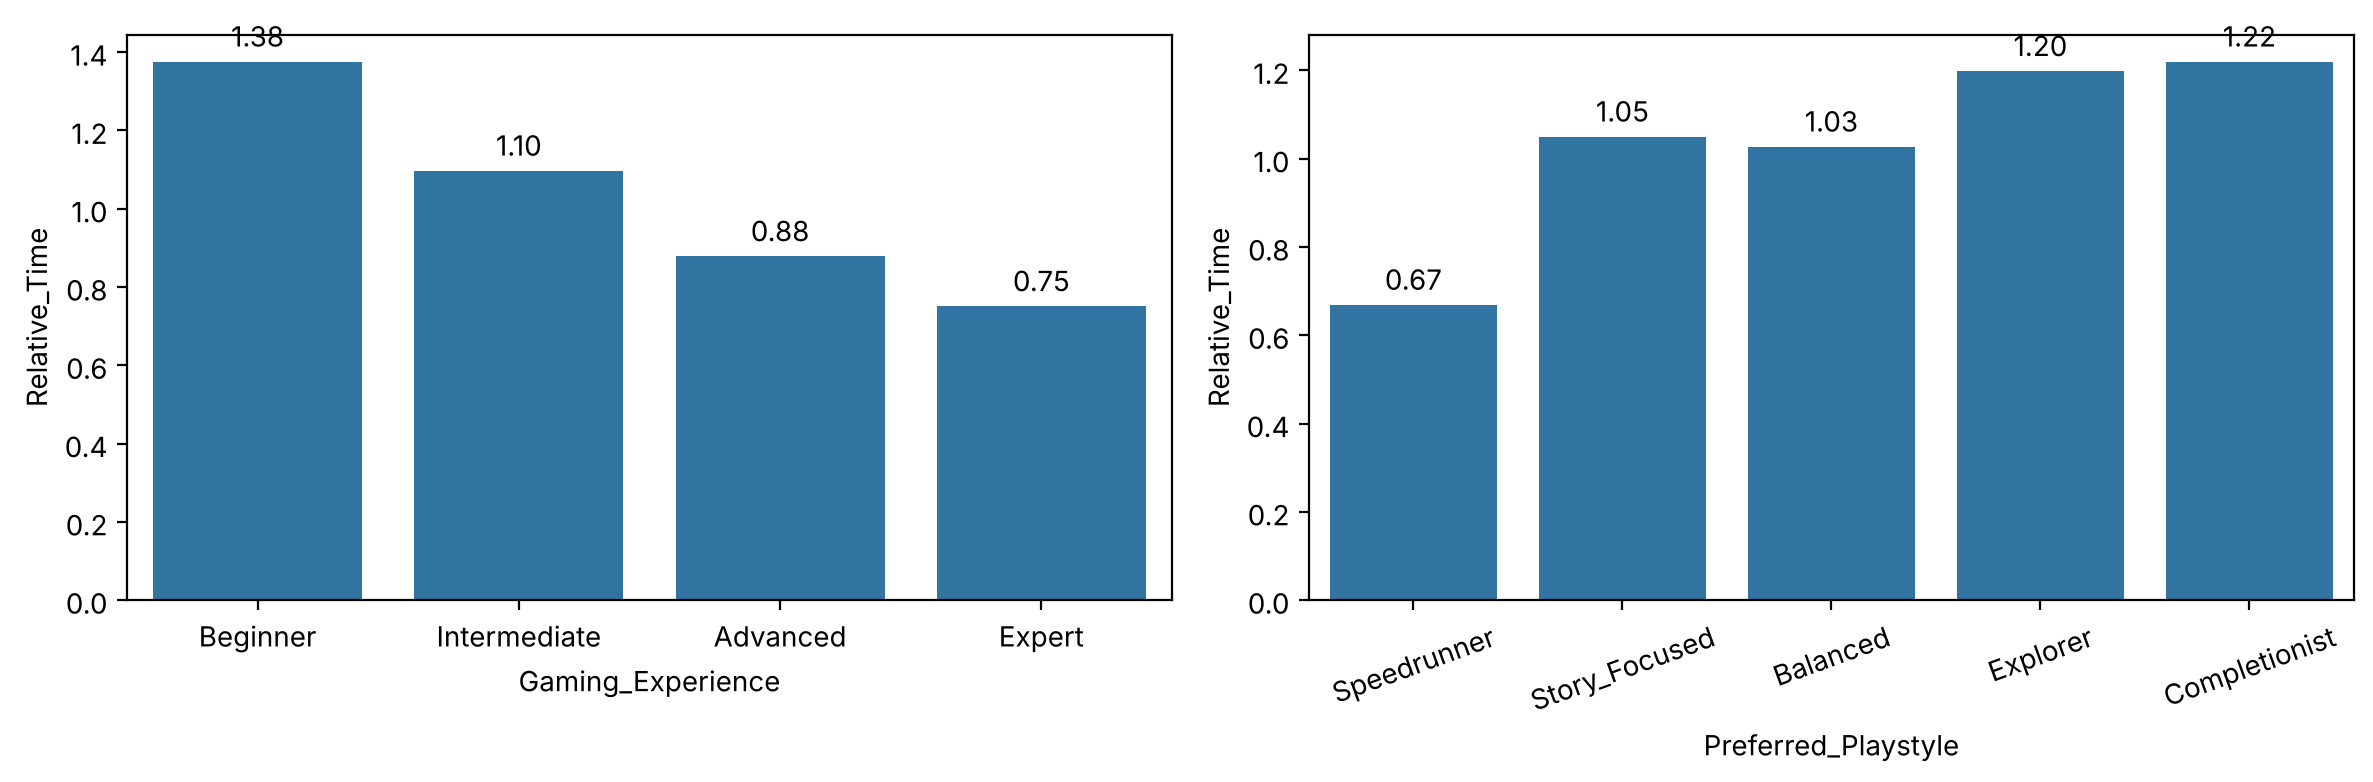

In [35]:
df_relative = df.copy()
df_relative['Relative_Time'] = df['Completion_Time_Hours'] / df.groupby('Game_ID')['Completion_Time_Hours'].transform('median')

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
ax4 = sns.barplot(data=df_relative, x='Gaming_Experience', y='Relative_Time', errorbar=None,
            order=['Beginner', 'Intermediate', 'Advanced', 'Expert'])
plt.subplot(1, 2, 2)
ax5 = sns.barplot(data=df_relative, x='Preferred_Playstyle', y='Relative_Time', errorbar=None,
            order=['Speedrunner', 'Story_Focused', 'Balanced', 'Explorer', 'Completionist'])
plt.xticks(rotation=20)
for container in ax4.containers:
    ax4.bar_label(container, fmt='%.2f', padding=3)
for container in ax5.containers:
    ax5.bar_label(container, fmt='%.2f', padding=3)
plt.tight_layout()
plt.show()

## Gameplay behaviour vs completion time

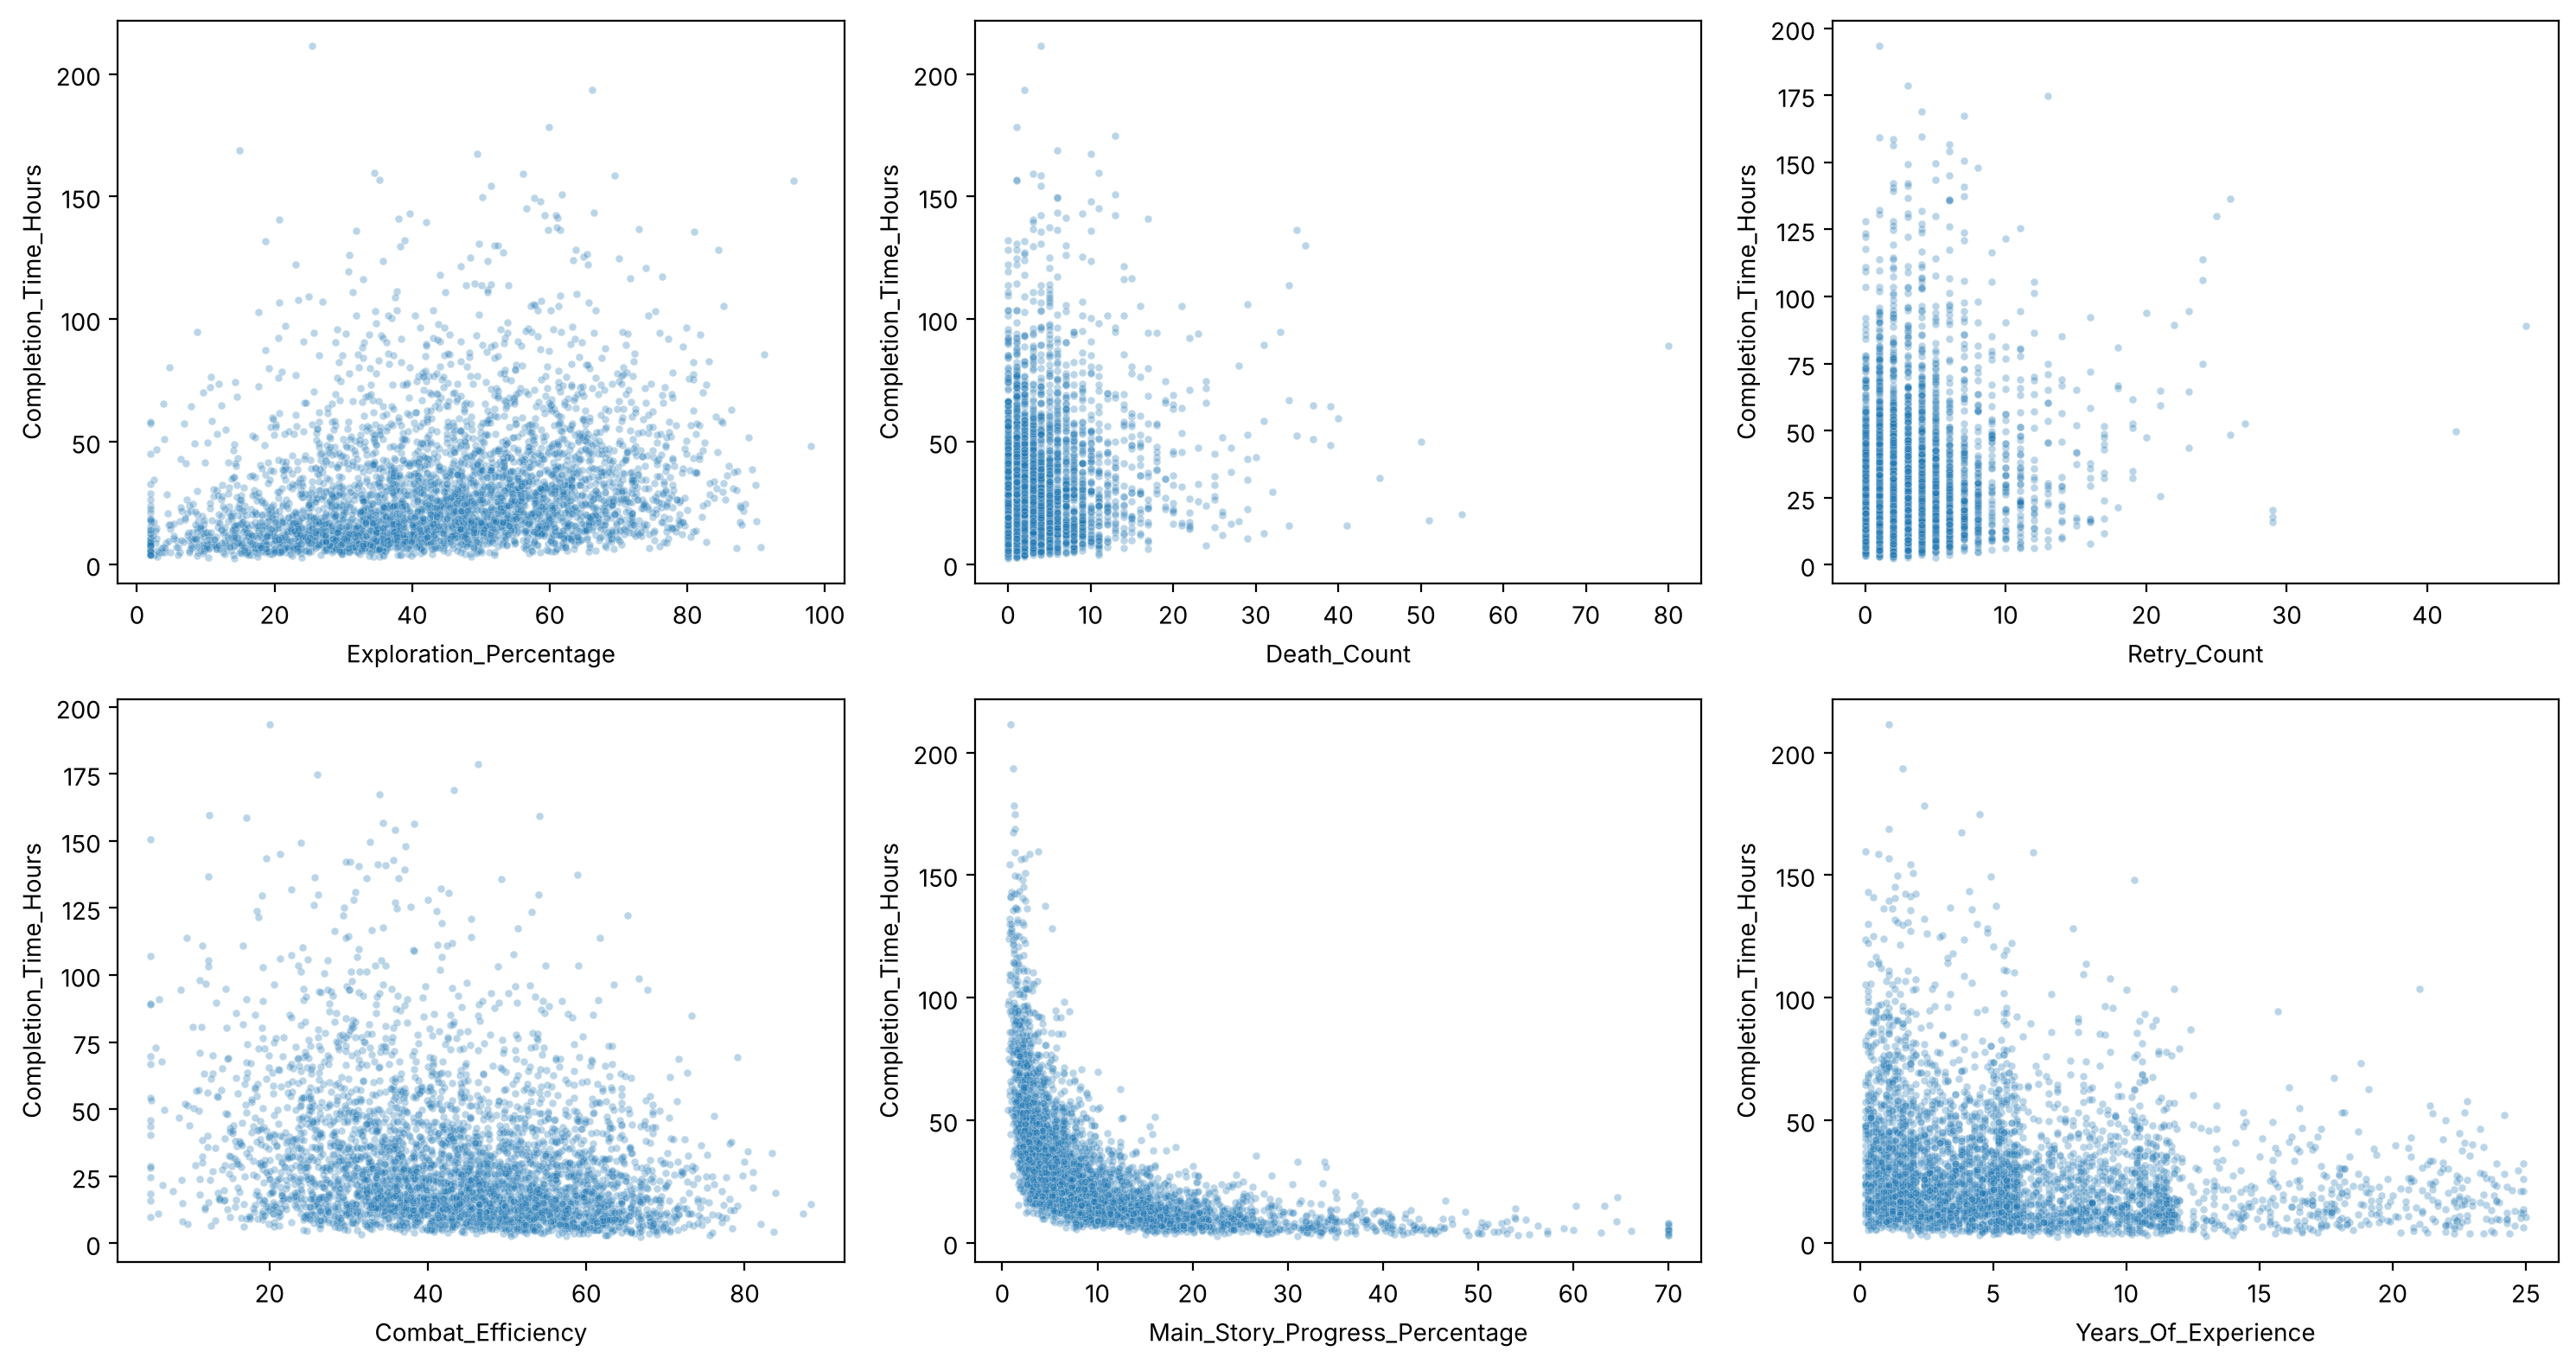

In [36]:
sample = df.sample(4000, random_state=42)
features = ['Exploration_Percentage', 'Death_Count', 'Retry_Count',
            'Combat_Efficiency', 'Main_Story_Progress_Percentage', 'Years_Of_Experience']

plt.figure(figsize=(15, 8))
for n, i in enumerate(features):
    plt.subplot(2, 3, n + 1)
    sns.scatterplot(data=sample, x=i, y='Completion_Time_Hours', alpha=0.3, s=10)
plt.tight_layout()
plt.show()

## Correlation heatmap

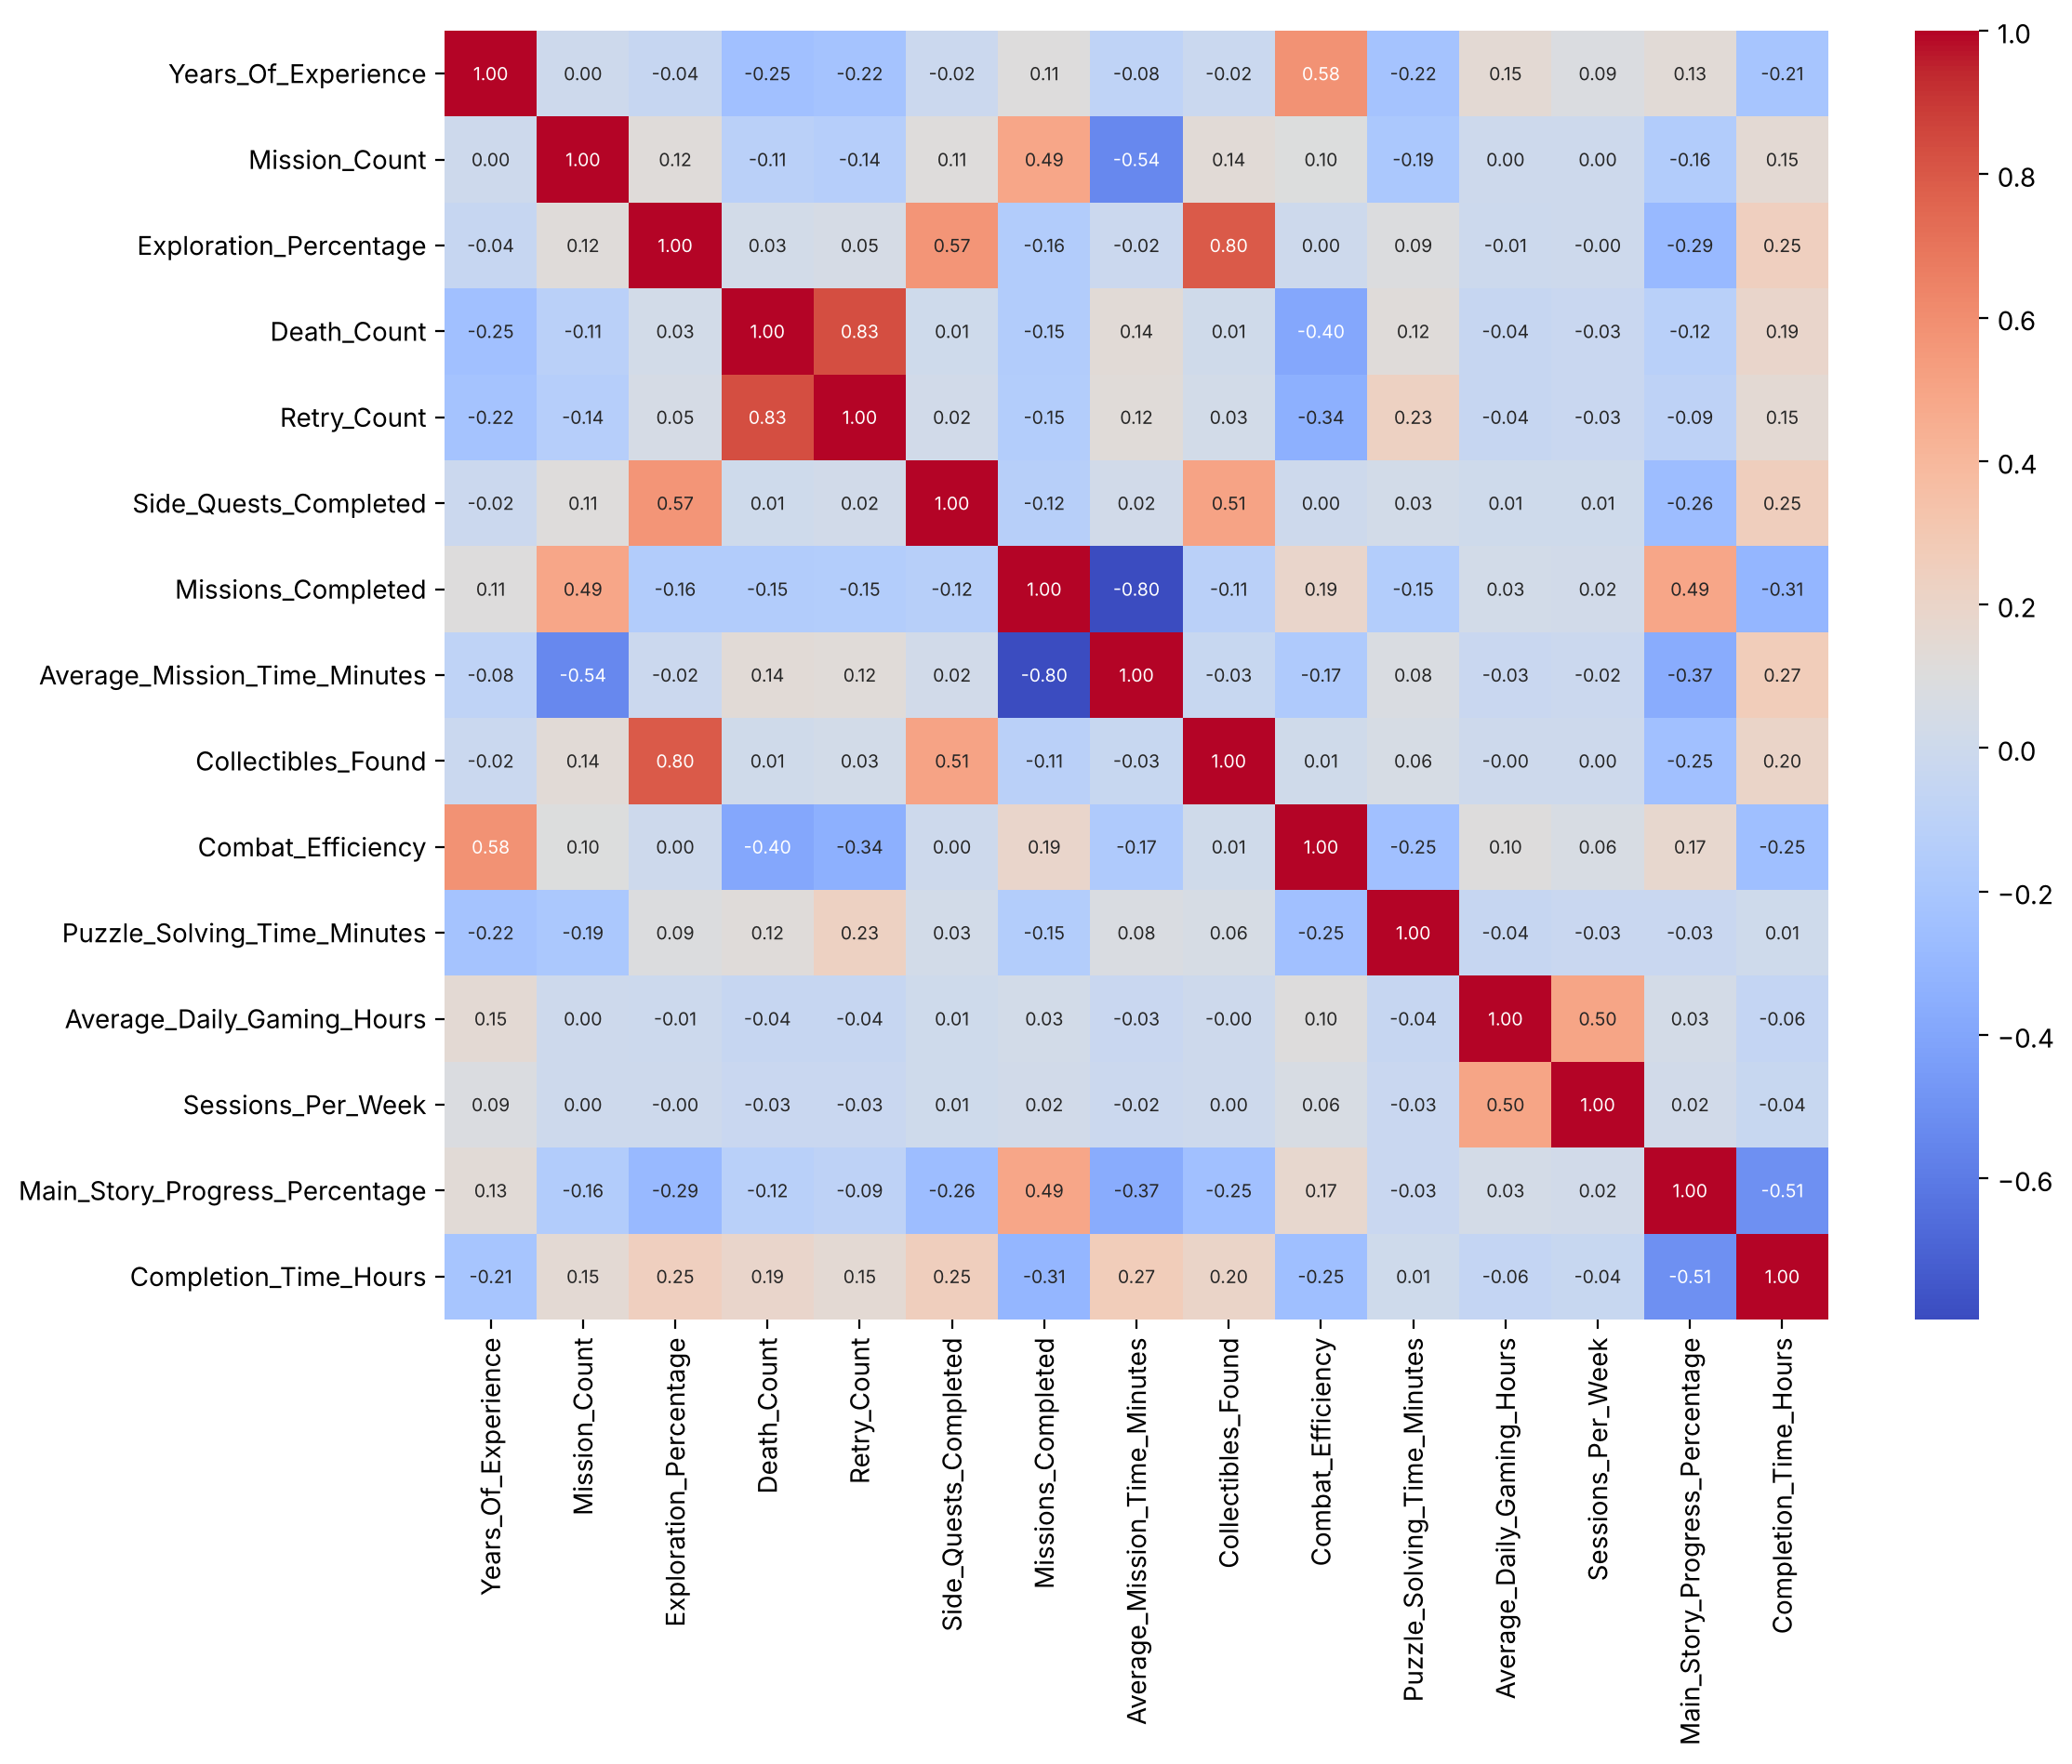

In [37]:
plt.figure(figsize=(12, 9))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.show()

## Feature engineering

In [38]:
df['Mission_Progression_Rate'] = df['Missions_Completed'] / 2
df['Retry_Intensity'] = df['Retry_Count'] / (df['Missions_Completed'] + 1)
df['Optional_Content_Per_Hour'] = (df['Collectibles_Found'] + df['Side_Quests_Completed']) / 2

df[['Missions_Completed', 'Mission_Progression_Rate', 'Retry_Count', 'Retry_Intensity', 'Optional_Content_Per_Hour']].head()

,Missions_Completed,Mission_Progression_Rate,Retry_Count,Retry_Intensity,Optional_Content_Per_Hour
0,1.0,0.5,4.0,2.0,11.5
1,0.0,0.0,5.0,5.0,6.0
2,1.0,0.5,5.0,2.5,4.5
3,0.0,0.0,5.0,5.0,4.0
4,0.0,0.0,2.0,2.0,2.5


## Feature selection

In [39]:
print(df.columns.tolist())

x = df.drop(['Player_ID', 'Game_ID', 'Game_Name', 'Completion_Time_Hours'], axis=1)
y = df['Completion_Time_Hours']

print(x.columns.tolist())
print(x.shape)
print(y.shape)

['Player_ID', 'Gaming_Experience', 'Years_Of_Experience', 'Preferred_Playstyle', 'Preferred_Difficulty', 'Game_ID', 'Game_Name', 'Game_Genre', 'Game_Difficulty', 'Open_World', 'Mission_Count', 'Main_Story_Complexity', 'Side_Quest_Availability', 'Puzzle_Intensity', 'Exploration_Percentage', 'Death_Count', 'Retry_Count', 'Side_Quests_Completed', 'Missions_Completed', 'Average_Mission_Time_Minutes', 'Collectibles_Found', 'Combat_Efficiency', 'Puzzle_Solving_Time_Minutes', 'Average_Daily_Gaming_Hours', 'Sessions_Per_Week', 'Main_Story_Progress_Percentage', 'Completion_Time_Hours', 'Mission_Progression_Rate', 'Retry_Intensity', 'Optional_Content_Per_Hour']
['Gaming_Experience', 'Years_Of_Experience', 'Preferred_Playstyle', 'Preferred_Difficulty', 'Game_Genre', 'Game_Difficulty', 'Open_World', 'Mission_Count', 'Main_Story_Complexity', 'Side_Quest_Availability', 'Puzzle_Intensity', 'Exploration_Percentage', 'Death_Count', 'Retry_Count', 'Side_Quests_Completed', 'Missions_Completed', 'Average_

## Train test split (by player)

In [40]:
players = df['Player_ID'].unique()
train_players, test_players = train_test_split(players, test_size=0.2, random_state=42)

train_rows = df['Player_ID'].isin(train_players)

x_train, x_test = x[train_rows].copy(), x[~train_rows].copy()
y_train, y_test = y[train_rows], y[~train_rows]

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)
print("Training players:", len(train_players))
print("Testing players:", len(test_players))
print("Players in both:", len(set(train_players) & set(test_players)))

(39798, 26)
(9833, 26)
(39798,)
(9833,)
Training players: 7990
Testing players: 1998
Players in both: 0


## Filling remaining missing values (training data only)

In [41]:
num_features = x.select_dtypes(include=np.number).columns.tolist()
cat_features = [i for i in x.columns if i not in num_features]

medians = {}
modes = {}

for i in num_features:
    medians[i] = x_train[i].median()
    x_train[i] = x_train[i].fillna(medians[i])
    x_test[i] = x_test[i].fillna(medians[i])

for i in cat_features:
    modes[i] = x_train[i].mode()[0]
    x_train[i] = x_train[i].fillna(modes[i])
    x_test[i] = x_test[i].fillna(modes[i])

print(x_train.isnull().sum().sum())
print(x_test.isnull().sum().sum())

0
0


## Encoding

In [42]:
x_train[cat_features].head()

,Gaming_Experience,Preferred_Playstyle,Preferred_Difficulty,Game_Genre,Game_Difficulty,Open_World,Main_Story_Complexity,Side_Quest_Availability,Puzzle_Intensity
1,Advanced,Balanced,Normal,Action,Hard,Yes,High,Yes,Medium
2,Advanced,Explorer,Normal,Adventure,Normal,No,Medium,No,Medium
4,Advanced,Balanced,Hard,RPG,Normal,No,High,Yes,Low
5,Expert,Speedrunner,Normal,RPG,Normal,Yes,High,Yes,Low
6,Intermediate,Speedrunner,Normal,RPG,Very_Hard,No,High,Yes,Low


In [43]:
x_train = pd.get_dummies(x_train, columns=cat_features, dtype=int)
x_test = pd.get_dummies(x_test, columns=cat_features, dtype=int)
x_test = x_test.reindex(columns=x_train.columns, fill_value=0)

print(x_train.shape)
print(x_test.shape)
x_train.head()

(39798, 49)
(9833, 49)


,Years_Of_Experience,Mission_Count,Exploration_Percentage,Death_Count,Retry_Count,Side_Quests_Completed,Missions_Completed,Average_Mission_Time_Minutes,Collectibles_Found,Combat_Efficiency,...,Open_World_No,Open_World_Yes,Main_Story_Complexity_High,Main_Story_Complexity_Low,Main_Story_Complexity_Medium,Side_Quest_Availability_No,Side_Quest_Availability_Yes,Puzzle_Intensity_High,Puzzle_Intensity_Low,Puzzle_Intensity_Medium
1,10.5,6.0,48.1,9.0,5.0,3.0,0.0,85.2,9.0,38.6,...,0,1,1,0,0,0,1,0,0,1
2,9.8,6.0,44.0,1.0,5.0,0.0,1.0,63.4,9.0,51.2,...,1,0,0,0,1,1,0,0,0,1
4,9.7,30.0,34.7,1.0,2.0,1.0,0.0,73.0,4.0,65.4,...,1,0,1,0,0,0,1,0,1,0
5,24.8,29.0,29.6,1.0,0.0,1.0,2.0,34.8,1.0,50.4,...,0,1,1,0,0,0,1,0,1,0
6,2.5,12.0,16.5,12.0,9.0,0.0,0.0,74.8,1.0,22.1,...,1,0,1,0,0,0,1,0,1,0


## Scaling

In [44]:
x_train[num_features].head()

,Years_Of_Experience,Mission_Count,Exploration_Percentage,Death_Count,Retry_Count,Side_Quests_Completed,Missions_Completed,Average_Mission_Time_Minutes,Collectibles_Found,Combat_Efficiency,Puzzle_Solving_Time_Minutes,Average_Daily_Gaming_Hours,Sessions_Per_Week,Main_Story_Progress_Percentage,Mission_Progression_Rate,Retry_Intensity,Optional_Content_Per_Hour
1,10.5,6.0,48.1,9.0,5.0,3.0,0.0,85.2,9.0,38.6,9.4,1.70,6.0,12.4,0.0,5.0,6.0
2,9.8,6.0,44.0,1.0,5.0,0.0,1.0,63.4,9.0,51.2,14.7,5.00,13.0,29.9,0.5,2.5,4.5
4,9.7,30.0,34.7,1.0,2.0,1.0,0.0,73.0,4.0,65.4,2.8,2.20,8.0,1.7,0.0,2.0,2.5
5,24.8,29.0,29.6,1.0,0.0,1.0,2.0,34.8,1.0,50.4,1.8,1.80,7.0,7.1,1.0,0.0,1.0
6,2.5,12.0,16.5,12.0,9.0,0.0,0.0,74.8,1.0,22.1,6.7,3.05,7.0,8.1,0.0,9.0,0.5


In [45]:
scaler = StandardScaler()
x_train[num_features] = scaler.fit_transform(x_train[num_features])
x_test[num_features] = scaler.transform(x_test[num_features])

x_train[num_features].head()

,Years_Of_Experience,Mission_Count,Exploration_Percentage,Death_Count,Retry_Count,Side_Quests_Completed,Missions_Completed,Average_Mission_Time_Minutes,Collectibles_Found,Combat_Efficiency,Puzzle_Solving_Time_Minutes,Average_Daily_Gaming_Hours,Sessions_Per_Week,Main_Story_Progress_Percentage,Mission_Progression_Rate,Retry_Intensity,Optional_Content_Per_Hour
1,0.854785,-0.852717,0.238164,0.978825,0.495314,0.762634,-0.813940,1.564704,0.092566,-0.336635,0.307209,-0.323459,0.114684,0.170411,-0.813940,1.044428,0.299678
2,0.721408,-0.852717,0.016045,-0.571672,0.495314,-0.947235,-0.417237,0.658160,0.092566,0.536044,1.249992,2.506483,2.600337,1.873048,-0.417237,0.190380,-0.188843
4,0.702355,0.217740,-0.487786,-0.571672,-0.375854,-0.377279,-0.813940,1.057372,-0.885122,1.519539,-0.866823,0.105320,0.824871,-0.870629,-0.813940,0.019571,-0.840204
5,3.579469,0.173138,-0.764080,-0.571672,-0.956633,-0.377279,-0.020534,-0.531158,-1.471734,0.480635,-1.044706,-0.237703,0.469777,-0.345244,-0.020534,-0.663668,-1.328725
6,-0.669514,-0.585103,-1.473776,1.560261,1.656872,-0.947235,-0.813940,1.132224,-1.471734,-1.479429,-0.173077,0.834244,0.469777,-0.247951,-0.813940,2.410904,-1.491565


## Training the models

In [46]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, random_state=42),
}

for name in models:
    models[name].fit(x_train, y_train)
    print(name, "trained")

Linear Regression trained


Decision Tree trained


Random Forest trained


Gradient Boosting trained


## Model evaluation

In [47]:
results = []

for name in models:
    train_pred = models[name].predict(x_train)
    test_pred = models[name].predict(x_test)
    results.append({
        'Model': name,
        'Train MAE': mean_absolute_error(y_train, train_pred),
        'Test MAE': mean_absolute_error(y_test, test_pred),
        'Train MSE': mean_squared_error(y_train, train_pred),
        'Test MSE': mean_squared_error(y_test, test_pred),
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Train R2': r2_score(y_train, train_pred),
        'Test R2': r2_score(y_test, test_pred),
    })

results = pd.DataFrame(results)
results.round(3)

,Model,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,11.255,11.270,294.844,284.613,17.171,16.870,0.534,0.536
1,Decision Tree,8.435,8.779,180.176,201.028,13.423,14.178,0.715,0.672
2,Random Forest,4.455,6.918,60.393,132.549,7.771,11.513,0.905,0.784
3,Gradient Boosting,7.115,7.274,131.075,140.216,11.449,11.841,0.793,0.772


## Overfitting check

In [48]:
results['R2 Gap'] = results['Train R2'] - results['Test R2']
results[['Model', 'Train R2', 'Test R2', 'R2 Gap']].round(3)

,Model,Train R2,Test R2,R2 Gap
0,Linear Regression,0.534,0.536,-0.002
1,Decision Tree,0.715,0.672,0.043
2,Random Forest,0.905,0.784,0.120
3,Gradient Boosting,0.793,0.772,0.021


## Actual vs predicted

In [49]:
def prediction_table(model):
    table = df.loc[~train_rows, ['Player_ID', 'Game_ID', 'Game_Name']].reset_index(drop=True)
    table['Actual_Completion_Time'] = y_test.values
    table['Predicted_Completion_Time'] = model.predict(x_test)
    table['Absolute_Error'] = (table['Actual_Completion_Time'] - table['Predicted_Completion_Time']).abs()
    table['Percentage_Error'] = table['Absolute_Error'] / table['Actual_Completion_Time'] * 100
    return table


tables = {}
for name in models:
    tables[name] = prediction_table(models[name])

best_name = results.loc[results['Test MAE'].idxmin(), 'Model']
best_model = models[best_name]
print("Best model:", best_name)

tables[best_name].head(30).round(1)

Best model: Random Forest


,Player_ID,Game_ID,Game_Name,Actual_Completion_Time,Predicted_Completion_Time,Absolute_Error,Percentage_Error
0,SYN_P01471,G004,Cyberpunk 2077,32.3,32.0,0.3,1.0
1,SYN_P05878,G021,Dark Souls II: Scholar of the First Sin,66.8,56.8,10.0,14.9
2,SYN_P08342,G027,Doom,13.5,11.4,2.1,15.6
3,SYN_P09136,G020,Dark Souls: Remastered,57.8,37.6,20.2,34.9
4,SYN_P04754,G063,The Wolf Among Us,14.4,14.0,0.4,2.9
5,SYN_P05900,G028,Doom Eternal,16.1,11.5,4.6,28.8
6,SYN_P02500,G011,Persona 5 Royal,98.2,81.8,16.4,16.7
7,SYN_P06934,G036,Hollow Knight,30.2,25.9,4.3,14.1
8,SYN_P07683,G065,Ori and the Blind Forest: Definitive Edition,7.3,11.4,4.1,56.4
9,SYN_P01786,G004,Cyberpunk 2077,23.6,29.5,5.9,24.9


## Prediction summary

In [50]:
summary = []

for name in tables:
    t = tables[name]
    error = t['Actual_Completion_Time'] - t['Predicted_Completion_Time']
    summary.append({
        'Model': name,
        'Test records': len(t),
        'MAE': t['Absolute_Error'].mean(),
        'RMSE': np.sqrt((error ** 2).mean()),
        'Average error': error.mean(),
        'Negative predictions': (t['Predicted_Completion_Time'] <= 0).sum(),
        'Within 2 hours': (t['Absolute_Error'] <= 2).sum(),
        'Within 5 hours': (t['Absolute_Error'] <= 5).sum(),
    })

pd.DataFrame(summary).round(2)

,Model,Test records,MAE,RMSE,Average error,Negative predictions,Within 2 hours,Within 5 hours
0,Linear Regression,9833,11.27,16.87,-0.06,405,1338,3198
1,Decision Tree,9833,8.78,14.18,-0.15,0,2274,4881
2,Random Forest,9833,6.92,11.51,-0.21,0,2984,5708
3,Gradient Boosting,9833,7.27,11.84,-0.05,0,2694,5383


## Actual vs predicted plots

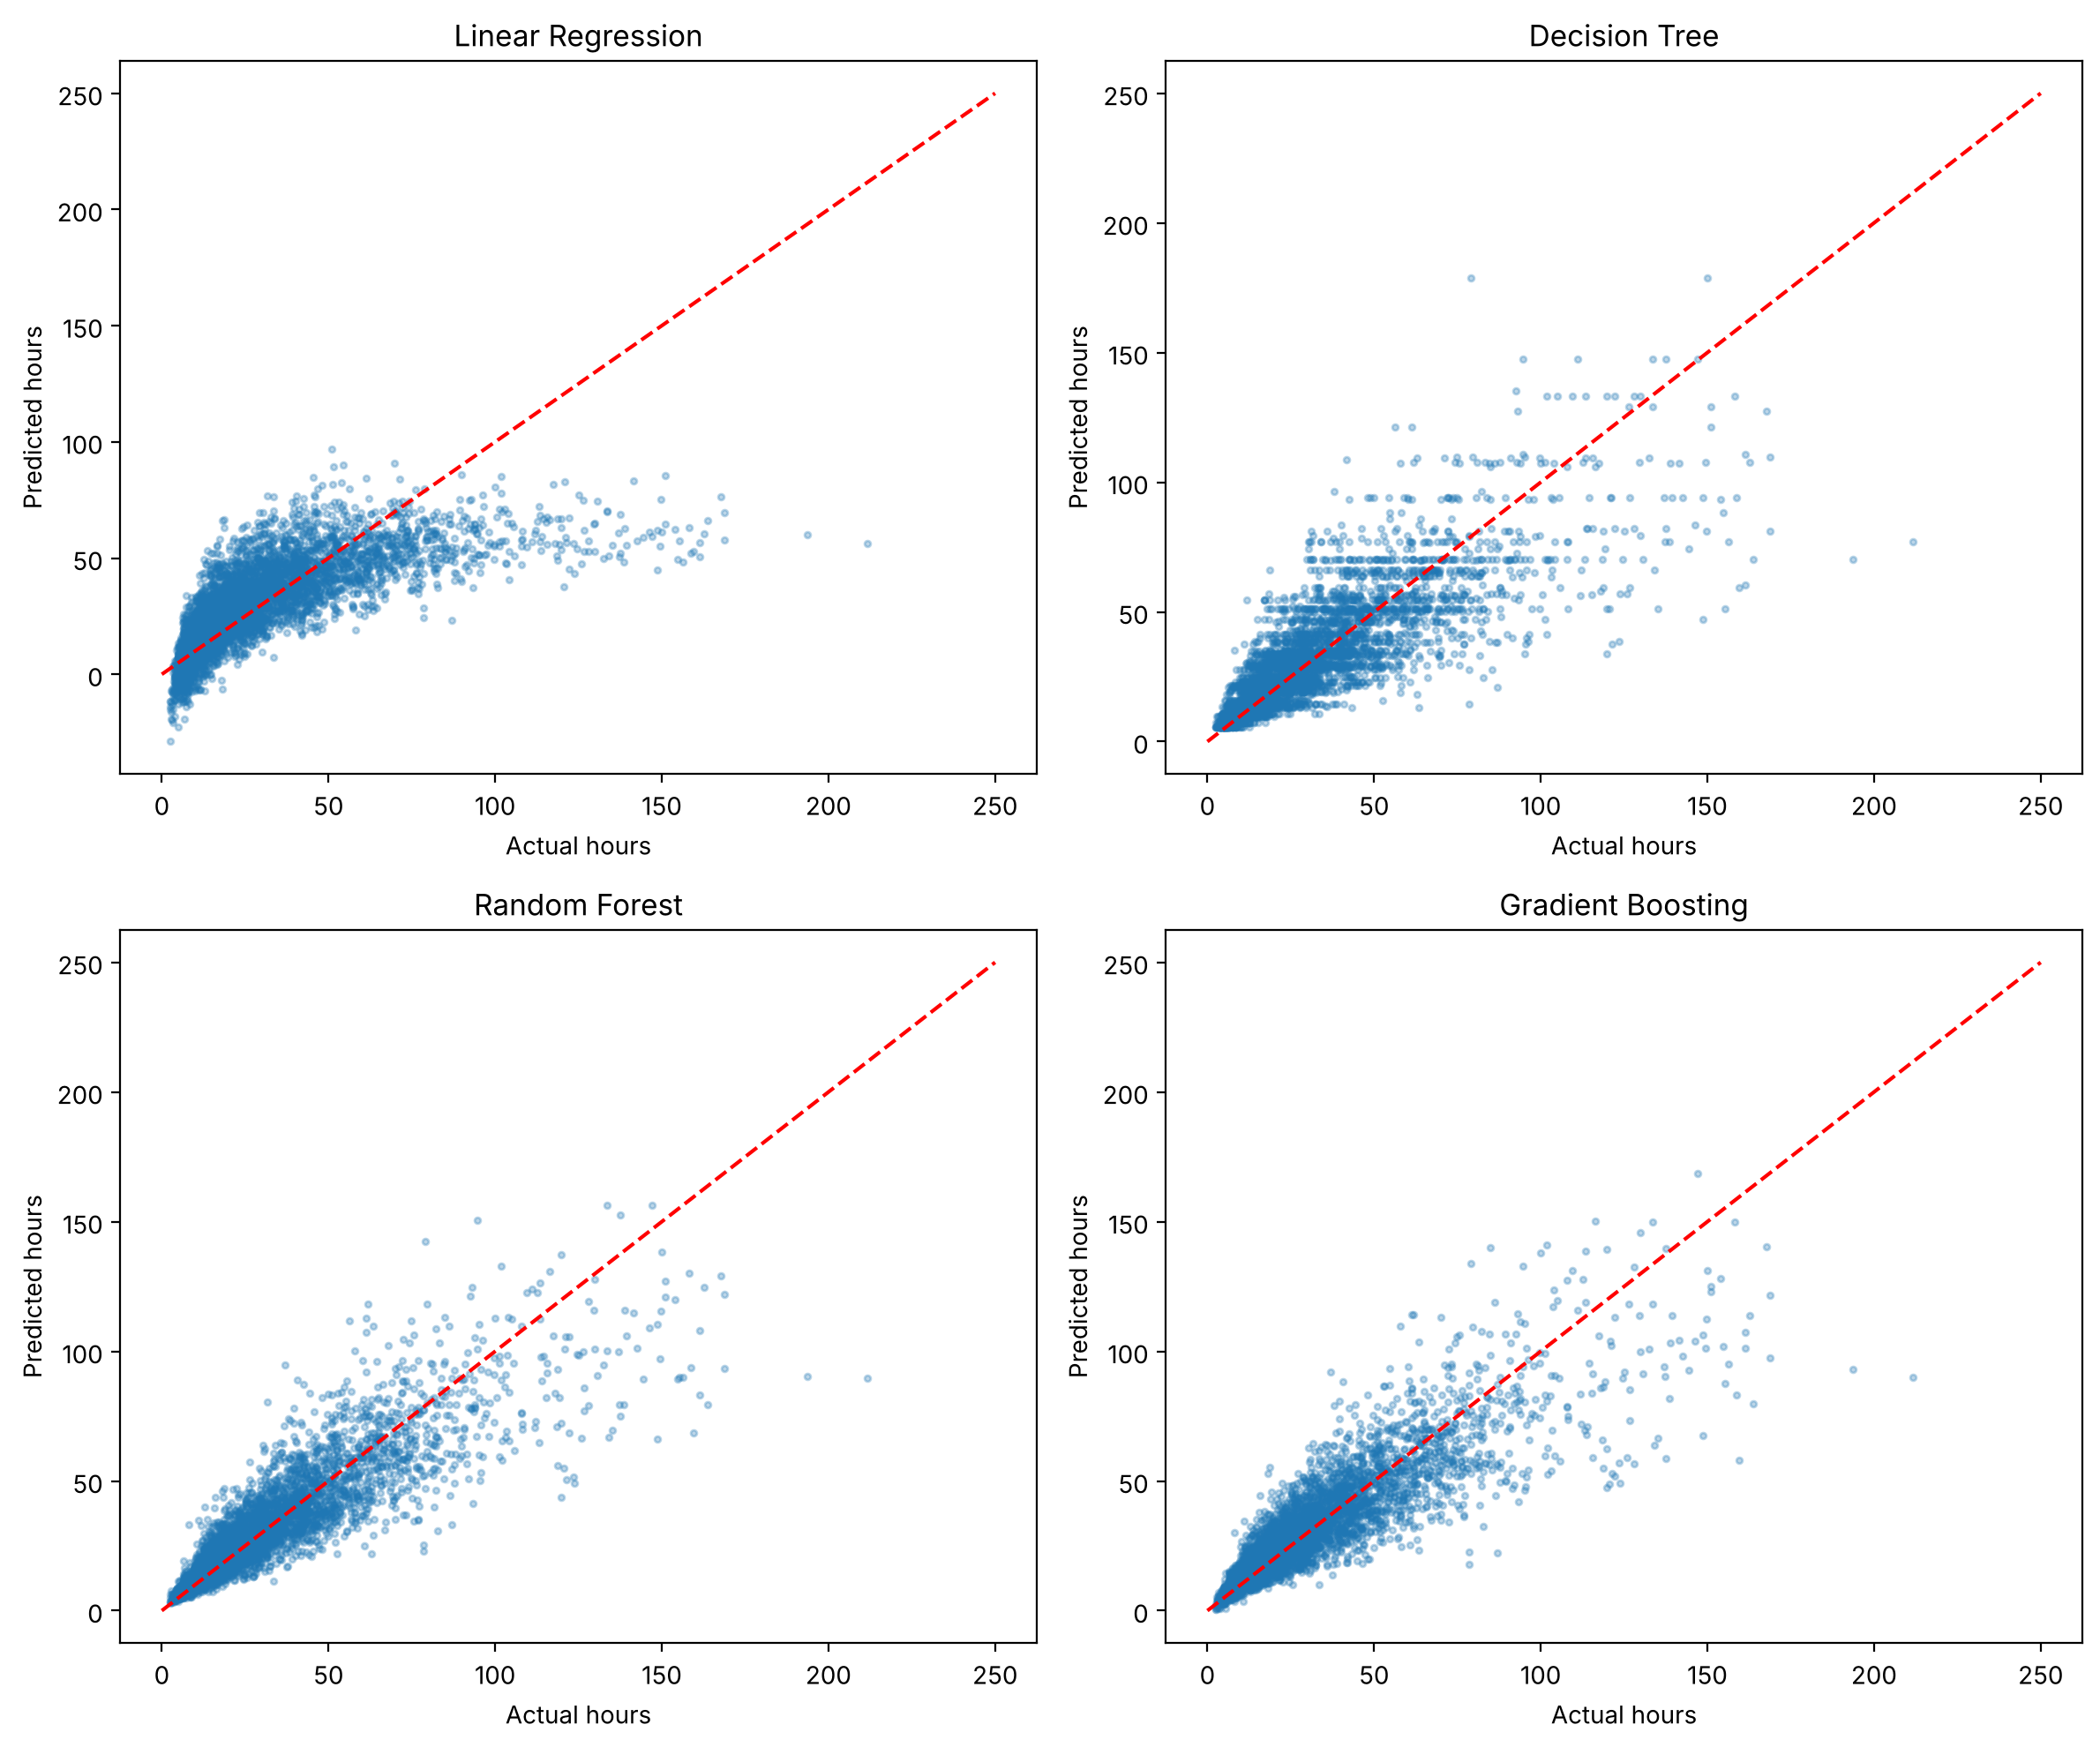

In [51]:
plt.figure(figsize=(12, 10))
for n, name in enumerate(tables):
    t = tables[name].sample(5000, random_state=42)
    plt.subplot(2, 2, n + 1)
    plt.scatter(t['Actual_Completion_Time'], t['Predicted_Completion_Time'], s=6, alpha=0.3)
    plt.plot([0, 250], [0, 250], 'r--')
    plt.xlabel('Actual hours')
    plt.ylabel('Predicted hours')
    plt.title(name)
plt.tight_layout()
plt.show()

## Residual distribution

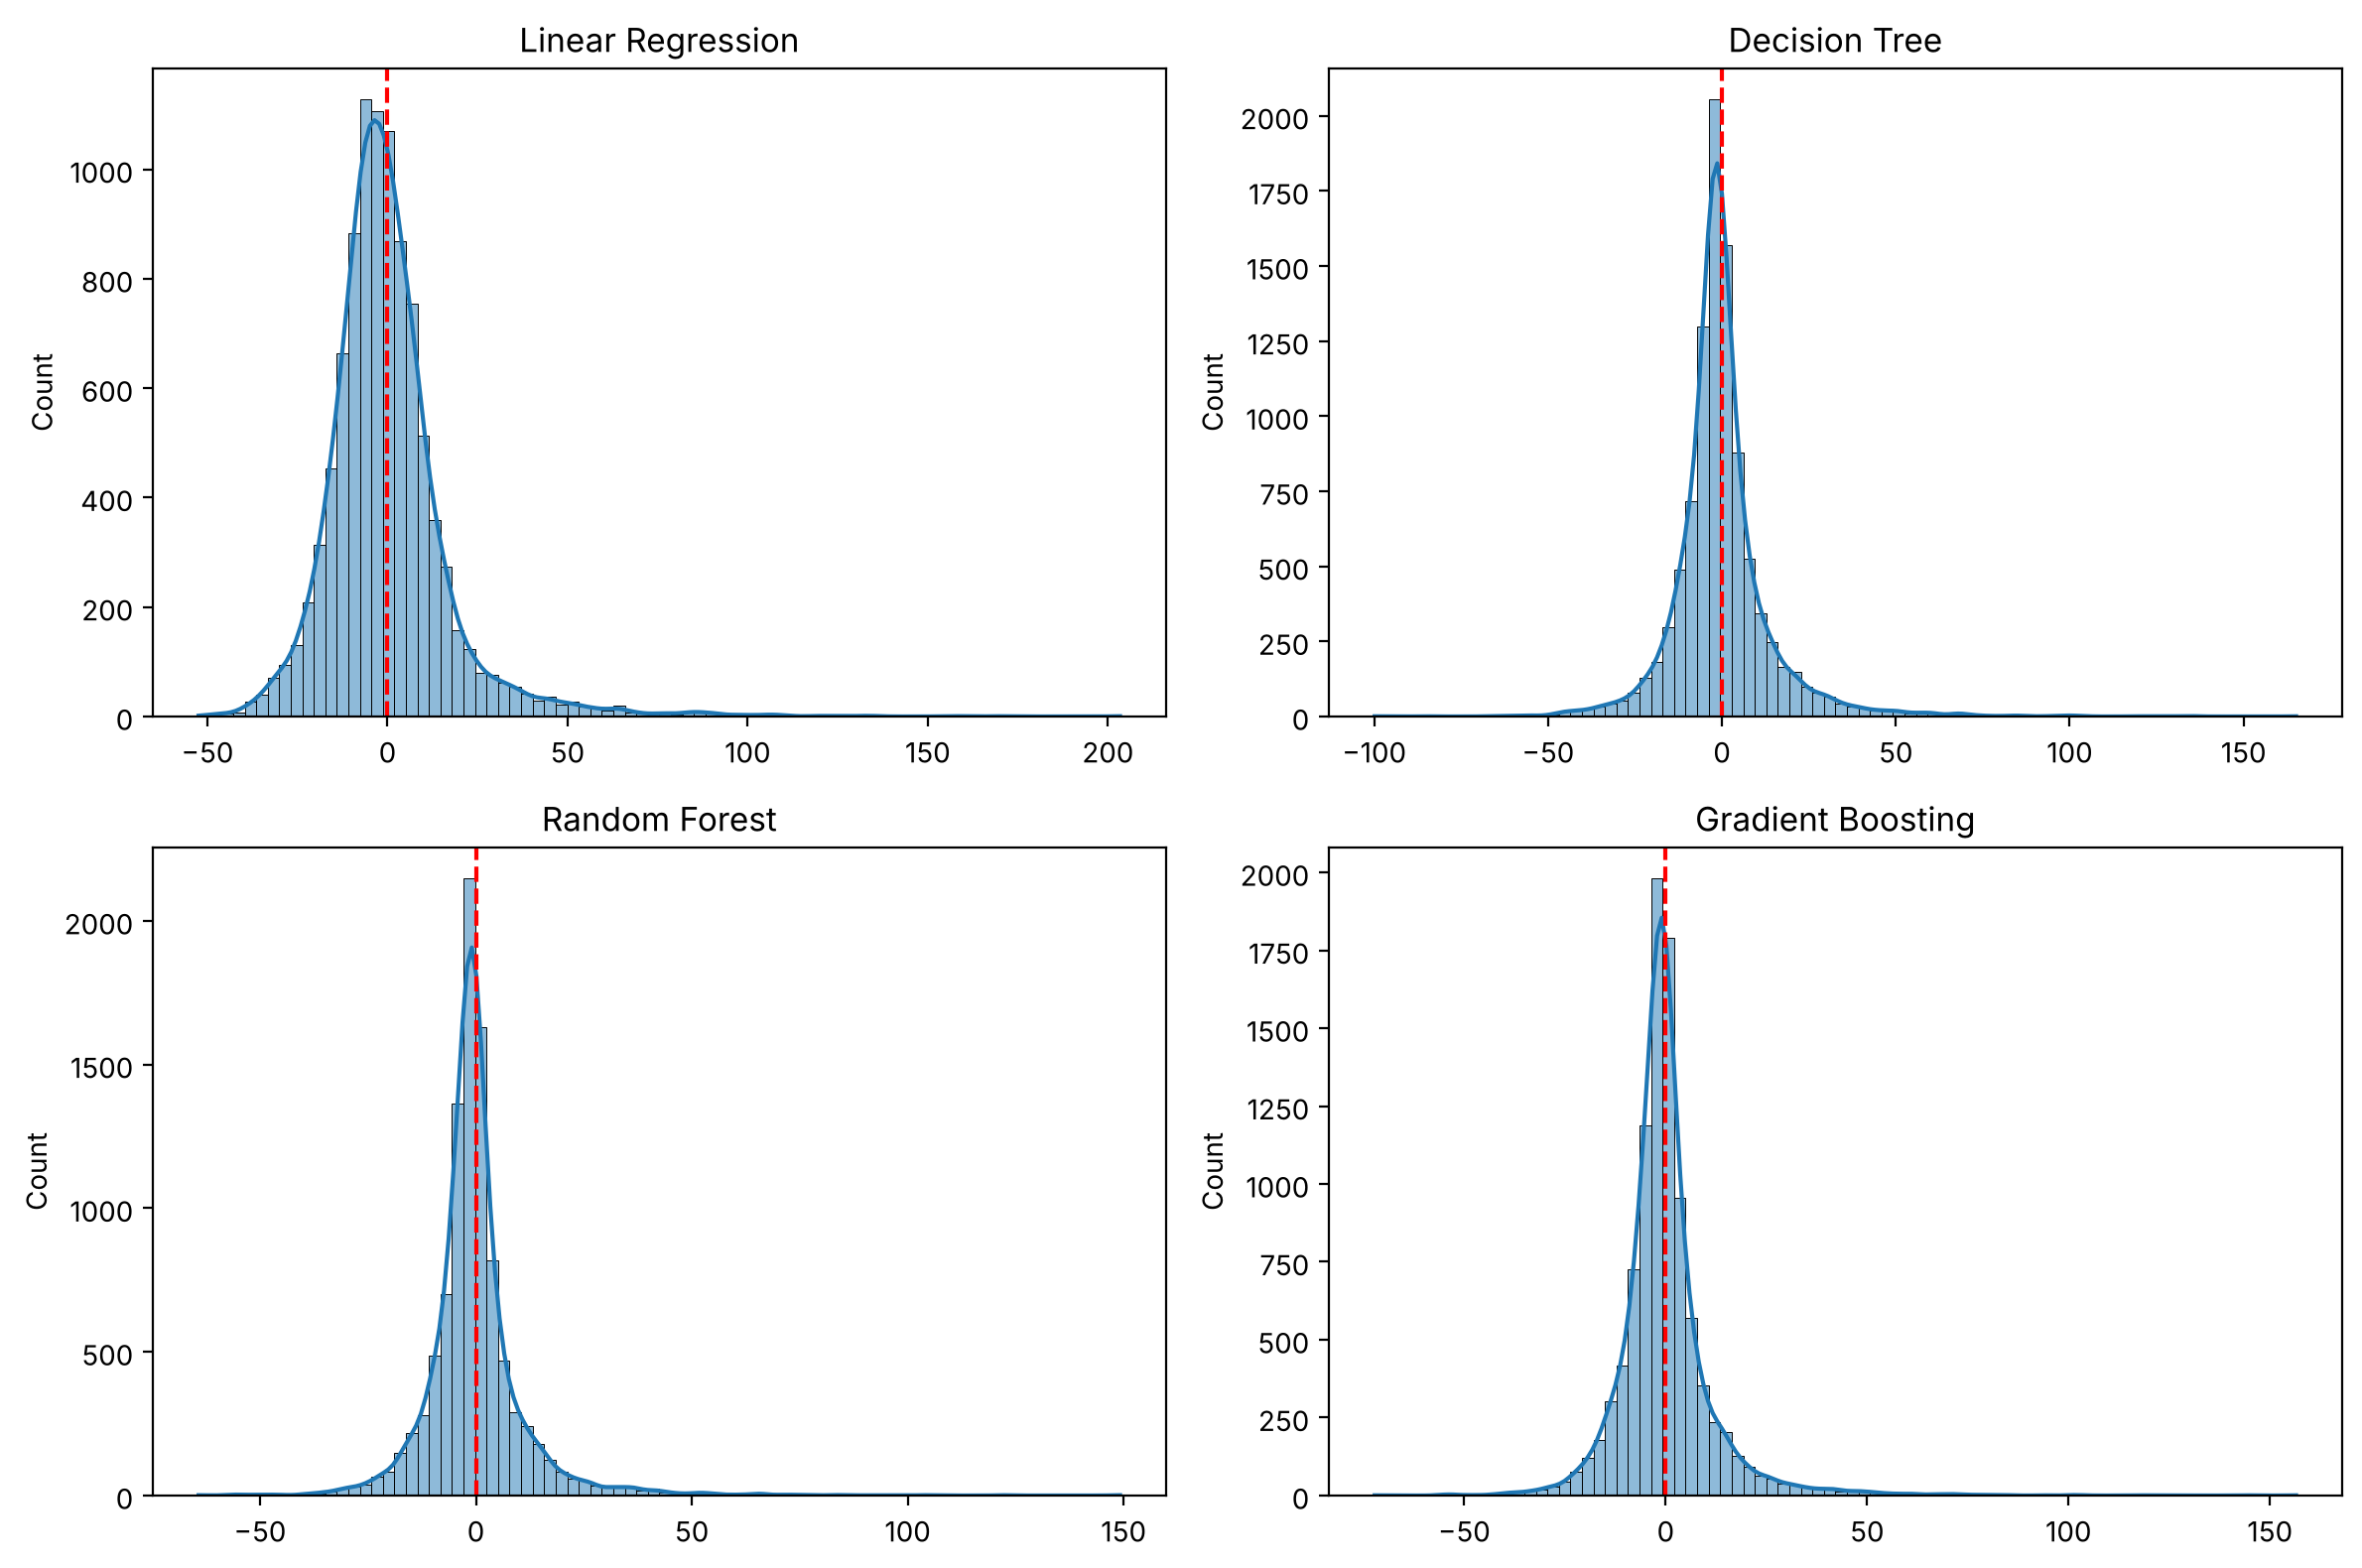

In [52]:
plt.figure(figsize=(12, 8))
for n, name in enumerate(tables):
    t = tables[name]
    plt.subplot(2, 2, n + 1)
    sns.histplot(t['Actual_Completion_Time'] - t['Predicted_Completion_Time'], bins=80, kde=True)
    plt.axvline(0, color='r', linestyle='--')
    plt.title(name)
plt.tight_layout()
plt.show()

## Error by game length

In [53]:
t = tables[best_name].copy()
t['Length'] = pd.cut(t['Actual_Completion_Time'], bins=[0, 5, 10, 20, 40, 1000],
                     labels=['under 5h', '5-10h', '10-20h', '20-40h', '40h+'])

t.groupby('Length', observed=True)[['Actual_Completion_Time', 'Predicted_Completion_Time', 'Absolute_Error']].mean().round(2)

,Actual_Completion_Time,Predicted_Completion_Time,Absolute_Error
Length,,,
under 5h,4.10,5.59,1.54
5-10h,7.82,9.70,2.27
10-20h,14.70,16.99,3.80
20-40h,28.62,30.96,6.47
40h+,64.99,58.89,14.34


## Most accurate predictions

In [54]:
tables[best_name].nsmallest(5, 'Absolute_Error').round(2)

,Player_ID,Game_ID,Game_Name,Actual_Completion_Time,Predicted_Completion_Time,Absolute_Error,Percentage_Error
1704,SYN_P01891,G059,A Plague Tale: Innocence,8.2,8.2,0.0,0.01
1485,SYN_P03046,G096,Dying Light,24.7,24.7,0.0,0.00
7788,SYN_P09898,G003,Baldur's Gate 3,76.8,76.8,0.0,0.00
3275,SYN_P03045,G081,Dead Island: Definitive Edition,11.0,11.0,0.0,0.02
9552,SYN_P06751,G031,Cuphead,11.2,11.2,0.0,0.03


## Least accurate predictions

In [55]:
tables[best_name].nlargest(5, 'Absolute_Error').round(2)

,Player_ID,Game_ID,Game_Name,Actual_Completion_Time,Predicted_Completion_Time,Absolute_Error,Percentage_Error
3225,SYN_P04014,G083,Valheim,261.9,112.73,149.17,56.96
1787,SYN_P03657,G011,Persona 5 Royal,231.2,82.37,148.83,64.37
2785,SYN_P02963,G002,The Witcher 3: Wild Hunt,199.1,75.78,123.32,61.94
7122,SYN_P01965,G011,Persona 5 Royal,211.6,89.81,121.79,57.56
7050,SYN_P05307,G003,Baldur's Gate 3,200.7,92.81,107.89,53.76


## Model comparison

In [56]:
comparison = results[['Model', 'Train MAE', 'Test MAE', 'Test RMSE', 'Test R2']].round(3)
comparison

,Model,Train MAE,Test MAE,Test RMSE,Test R2
0,Linear Regression,11.255,11.270,16.870,0.536
1,Decision Tree,8.435,8.779,14.178,0.672
2,Random Forest,4.455,6.918,11.513,0.784
3,Gradient Boosting,7.115,7.274,11.841,0.772


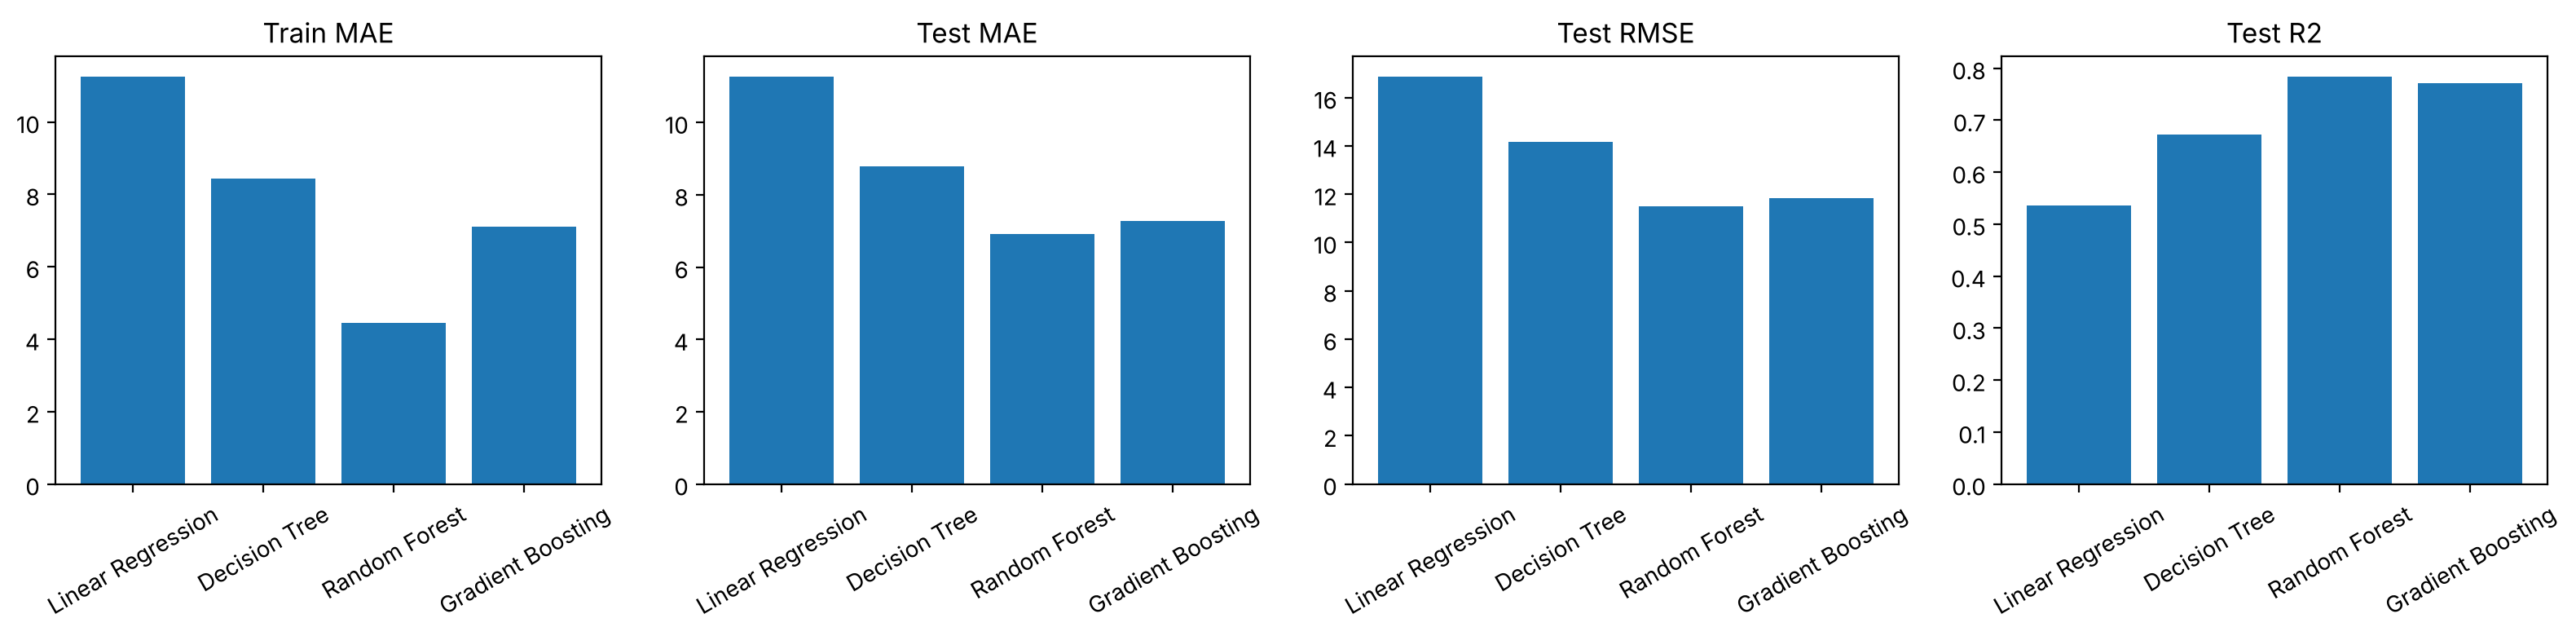

In [57]:
plt.figure(figsize=(16, 4))
for n, col in enumerate(['Train MAE', 'Test MAE', 'Test RMSE', 'Test R2']):
    plt.subplot(1, 4, n + 1)
    plt.bar(comparison['Model'], comparison[col])
    plt.title(col)
    plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Feature importance

Random Forest
Main_Story_Progress_Percentage    0.6173
Mission_Count                     0.0646
Combat_Efficiency                 0.0314
Years_Of_Experience               0.0299
Exploration_Percentage            0.0248
Game_Genre_RPG                    0.0220
Average_Mission_Time_Minutes      0.0189
Puzzle_Solving_Time_Minutes       0.0181
Main_Story_Complexity_High        0.0151
Game_Genre_Survival               0.0140
Preferred_Difficulty_Easy         0.0121
Average_Daily_Gaming_Hours        0.0095
Death_Count                       0.0092
Game_Difficulty_Normal            0.0090
Optional_Content_Per_Hour         0.0081
dtype: float64


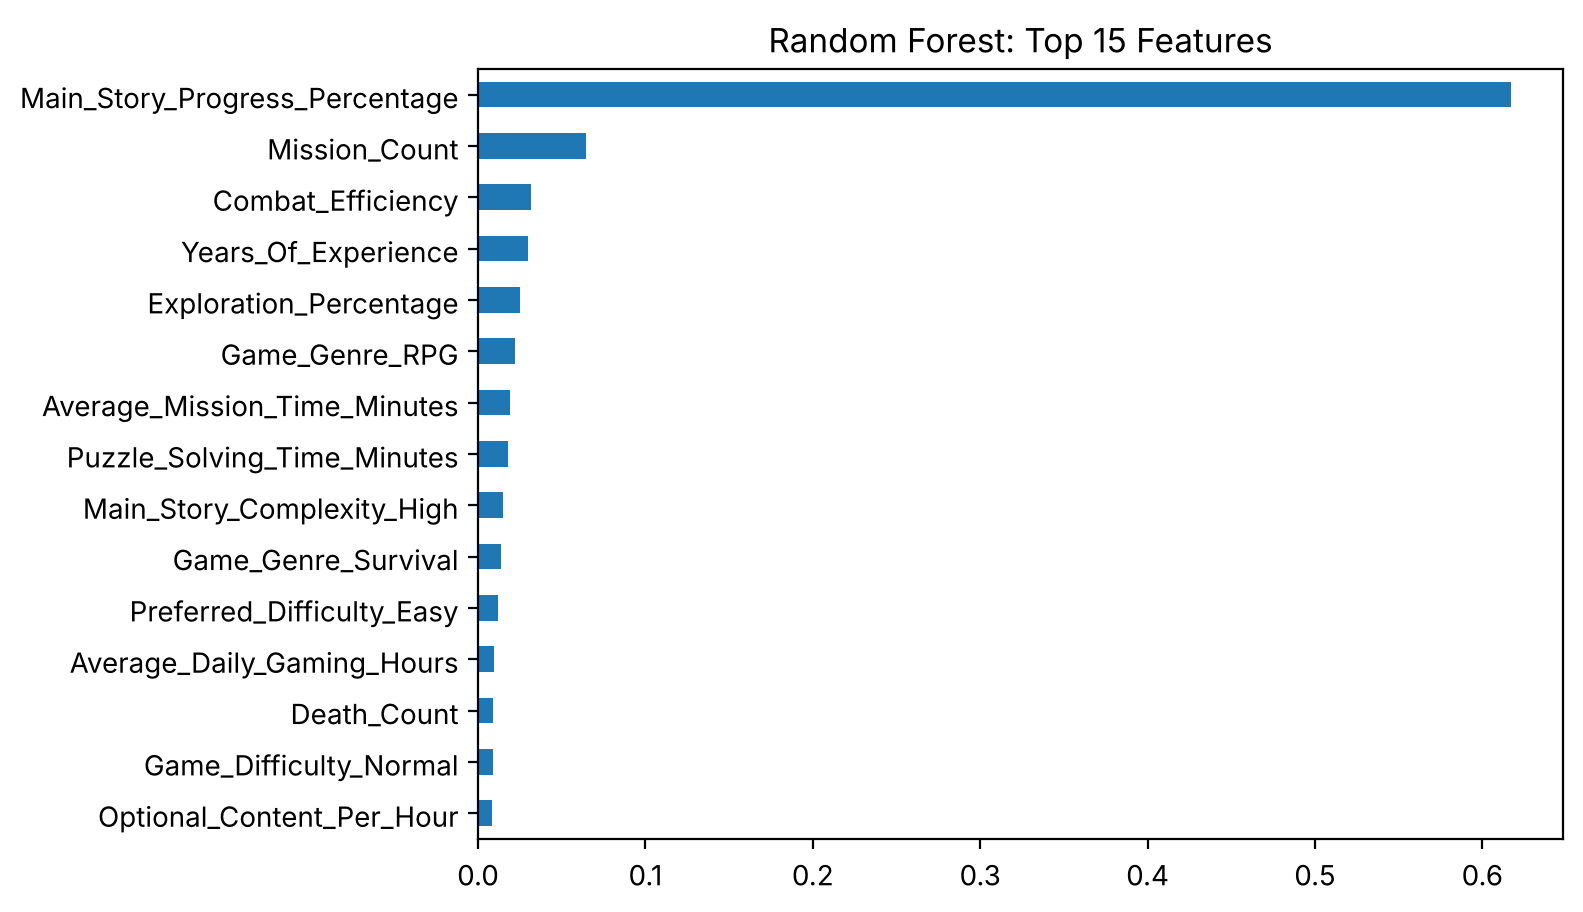

Gradient Boosting
Main_Story_Progress_Percentage    0.6847
Mission_Count                     0.0846
Game_Genre_RPG                    0.0339
Main_Story_Complexity_High        0.0337
Game_Genre_Survival               0.0216
Preferred_Difficulty_Easy         0.0175
Years_Of_Experience               0.0146
Combat_Efficiency                 0.0125
Game_Difficulty_Normal            0.0092
Game_Genre_Action                 0.0081
Main_Story_Complexity_Medium      0.0080
Open_World_No                     0.0058
Open_World_Yes                    0.0056
Average_Mission_Time_Minutes      0.0056
Gaming_Experience_Beginner        0.0054
dtype: float64


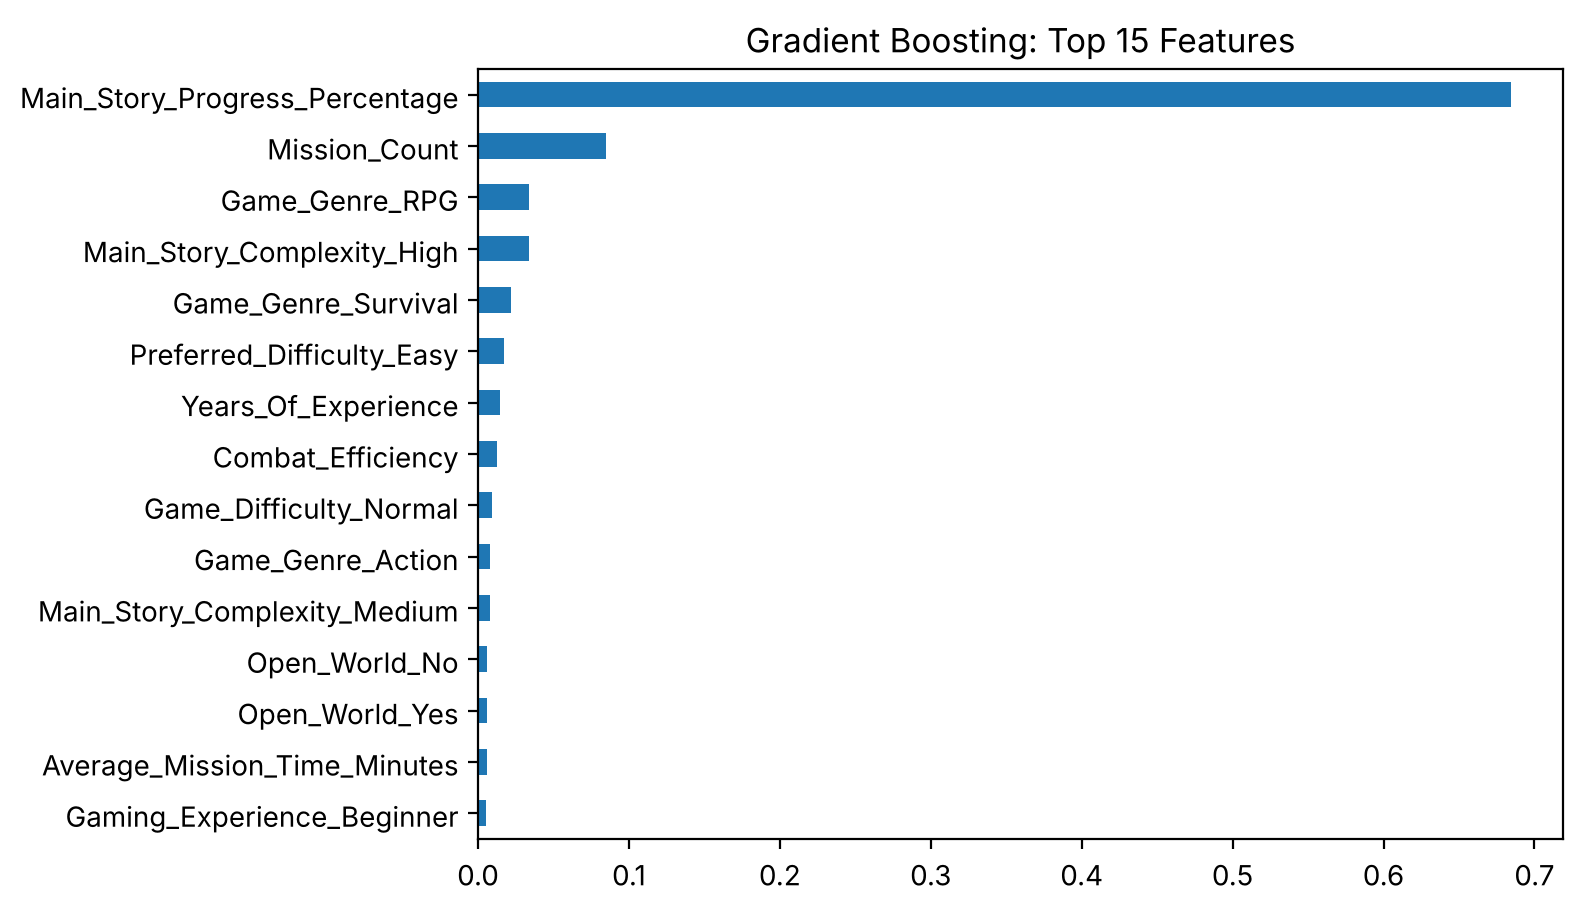

In [58]:
for name in ['Random Forest', 'Gradient Boosting']:
    importance = pd.Series(models[name].feature_importances_, index=x_train.columns).sort_values(ascending=False)
    print(name)
    print(importance.head(15).round(4))
    importance.head(15).sort_values().plot(kind='barh', figsize=(7, 5), title=name + ': Top 15 Features')
    plt.show()

## Prediction function

In [59]:
def predict_completion_time(game_name, player):
    row = {**medians, **modes}
    game = df[df['Game_Name'] == game_name].iloc[0]
    for i in game_cols:
        row[i] = game[i]
    row.update(player)
    row['Mission_Progression_Rate'] = row['Missions_Completed'] / 2
    row['Retry_Intensity'] = row['Retry_Count'] / (row['Missions_Completed'] + 1)
    row['Optional_Content_Per_Hour'] = (row['Collectibles_Found'] + row['Side_Quests_Completed']) / 2

    new = pd.DataFrame([row])[x.columns]
    new = pd.get_dummies(new, columns=cat_features, dtype=int).reindex(columns=x_train.columns, fill_value=0)
    new[num_features] = scaler.transform(new[num_features])
    return best_model.predict(new)[0]

## Prediction examples (model predictions)

In [60]:
examples = [
    ('Portal 2', {'Gaming_Experience': 'Expert', 'Years_Of_Experience': 14, 'Preferred_Playstyle': 'Speedrunner',
                  'Preferred_Difficulty': 'Hard', 'Exploration_Percentage': 12, 'Death_Count': 1, 'Retry_Count': 3,
                  'Missions_Completed': 4, 'Combat_Efficiency': 80, 'Main_Story_Progress_Percentage': 30}),
    ('The Witcher 3: Wild Hunt', {'Gaming_Experience': 'Beginner', 'Years_Of_Experience': 1, 'Preferred_Playstyle': 'Completionist',
                                  'Preferred_Difficulty': 'Easy', 'Exploration_Percentage': 70, 'Death_Count': 9, 'Retry_Count': 8,
                                  'Missions_Completed': 2, 'Combat_Efficiency': 28, 'Collectibles_Found': 20,
                                  'Side_Quests_Completed': 4, 'Main_Story_Progress_Percentage': 2}),
    ('The Witcher 3: Wild Hunt', {'Gaming_Experience': 'Expert', 'Years_Of_Experience': 15, 'Preferred_Playstyle': 'Speedrunner',
                                  'Preferred_Difficulty': 'Hard', 'Exploration_Percentage': 15, 'Death_Count': 1, 'Retry_Count': 1,
                                  'Missions_Completed': 5, 'Combat_Efficiency': 82, 'Collectibles_Found': 3,
                                  'Side_Quests_Completed': 0, 'Main_Story_Progress_Percentage': 6}),
    ('Hollow Knight', {'Gaming_Experience': 'Intermediate', 'Years_Of_Experience': 4, 'Preferred_Playstyle': 'Balanced',
                       'Preferred_Difficulty': 'Normal', 'Exploration_Percentage': 35, 'Death_Count': 8, 'Retry_Count': 7,
                       'Missions_Completed': 1, 'Combat_Efficiency': 50, 'Main_Story_Progress_Percentage': 8}),
    ('Elden Ring', {'Gaming_Experience': 'Advanced', 'Years_Of_Experience': 8, 'Preferred_Playstyle': 'Explorer',
                    'Preferred_Difficulty': 'Hard', 'Exploration_Percentage': 65, 'Death_Count': 15, 'Retry_Count': 12,
                    'Missions_Completed': 0, 'Combat_Efficiency': 48, 'Main_Story_Progress_Percentage': 3}),
    ('Stray', {'Gaming_Experience': 'Beginner', 'Years_Of_Experience': 1, 'Preferred_Playstyle': 'Story_Focused',
               'Preferred_Difficulty': 'Easy', 'Exploration_Percentage': 40, 'Death_Count': 2, 'Retry_Count': 2,
               'Missions_Completed': 3, 'Combat_Efficiency': 35, 'Main_Story_Progress_Percentage': 25}),
]

for game_name, player in examples:
    predicted = predict_completion_time(game_name, player)
    typical = df[df['Game_Name'] == game_name]['Completion_Time_Hours'].median()
    print(f"{game_name} | {player['Gaming_Experience']} {player['Preferred_Playstyle']}: "
          f"predicted {predicted:.1f} hours (median player in data: {typical:.1f} hours)")

Portal 2 | Expert Speedrunner: predicted 5.9 hours (median player in data: 8.9 hours)
The Witcher 3: Wild Hunt | Beginner Completionist: predicted 86.3 hours (median player in data: 52.0 hours)


The Witcher 3: Wild Hunt | Expert Speedrunner: predicted 26.6 hours (median player in data: 52.0 hours)
Hollow Knight | Intermediate Balanced: predicted 16.9 hours (median player in data: 27.3 hours)
Elden Ring | Advanced Explorer: predicted 52.6 hours (median player in data: 61.0 hours)


Stray | Beginner Story_Focused: predicted 7.2 hours (median player in data: 5.2 hours)


## Saving the model

In [61]:
joblib.dump(best_model, 'best_model.joblib')
joblib.dump(scaler, 'scaler.joblib')

['scaler.joblib']

## Final verification

In [62]:
print("Original records:", len(df_original), "| cleaned records:", len(df))
print("Players:", df['Player_ID'].nunique())
print("Games:", df['Game_ID'].nunique(), "| game names:", df['Game_Name'].nunique())
print("All completion times positive:", (df['Completion_Time_Hours'] > 0).all())
print("Player details consistent:", (df.groupby('Player_ID')[player_cols].nunique() > 1).sum().sum() == 0)
print("Game details consistent:", (df.groupby('Game_ID')[game_cols + ['Game_Name']].nunique() > 1).sum().sum() == 0)
print("Players in both train and test:", len(set(train_players) & set(test_players)))
print("Missing values in model inputs:", x_train.isnull().sum().sum() + x_test.isnull().sum().sum())
print("MAE recomputed matches:", np.isclose(results.loc[results['Model'] == best_name, 'Test MAE'].values[0],
                                            tables[best_name]['Absolute_Error'].mean()))

Original records: 51250 | cleaned records: 49631
Players: 9988
Games: 100 | game names: 100
All completion times positive: True
Player details consistent: True
Game details consistent: True
Players in both train and test: 0
Missing values in model inputs: 0
MAE recomputed matches: True


## Conclusion

In [63]:
best = results[results['Model'] == best_name].iloc[0]
t = tables[best_name]

print("Records after cleaning:", len(df), "| players:", df['Player_ID'].nunique(), "| games:", df['Game_ID'].nunique())
print("Features:", len(num_features), "numerical +", len(cat_features), "categorical ->", x_train.shape[1], "after encoding")
print("Best model:", best_name)
print("Test MAE:", round(best['Test MAE'], 2), "hours | Test RMSE:", round(best['Test RMSE'], 2), "hours | Test R2:", round(best['Test R2'], 3))
print("Predictions within 2 hours:", round((t['Absolute_Error'] <= 2).mean() * 100, 1), "%")
print("Predictions within 5 hours:", round((t['Absolute_Error'] <= 5).mean() * 100, 1), "%")
print(comparison)

Records after cleaning: 49631 | players: 9988 | games: 100
Features: 17 numerical + 9 categorical -> 49 after encoding
Best model: Random Forest
Test MAE: 6.92 hours | Test RMSE: 11.51 hours | Test R2: 0.784
Predictions within 2 hours: 30.3 %
Predictions within 5 hours: 58.0 %
               Model  Train MAE  Test MAE  Test RMSE  Test R2
0  Linear Regression     11.255    11.270     16.870    0.536
1      Decision Tree      8.435     8.779     14.178    0.672
2      Random Forest      4.455     6.918     11.513    0.784
3  Gradient Boosting      7.115     7.274     11.841    0.772
